# Case Study: Exploratory Data Analysis, Statistical Modeling, and Deep Learning for Bank Term Deposit Subscription Prediction
### Course: U21ADP05 — Exploratory Data Analysis and Visualization (Assignment II)
**Department of Artificial Intelligence and Data Science, KPR Institute of Engineering and Technology**  
**Student Name:** AJAY SABARISH A | **Roll Number:** 24AD007  
**Academic Year:** 2026–2027 (Odd Semester) | **Year/Semester:** III-YR / V Semester  
**Faculty In-Charge:** Mr. Rushikesh Kadam | **Submission Date:** 15 October 2026  
**Repository:** https://github.com/Ajay-0301/EDA  

---
### Executive Overview & Problem Context
In retail banking, outbound telemarketing campaigns represent one of the primary avenues for selling long-term financial products such as fixed-term deposits. However, unsolicited phone campaigns entail significant operational costs and risk client fatigue. Determining customer propensity to subscribe before outreach—conditioned on demographic characteristics, historical banking relationships, prior campaign interactions, and prevailing macroeconomic indicators—allows financial institutions to allocate telemarketing resources effectively while elevating conversion yields.

This project delivers an end-to-end exploratory data analysis (EDA), rigorous parametric and non-parametric statistical hypothesis testing, distribution-fitting analysis (continuous and discrete), and a reproducible Deep Learning Multilayer Perceptron (MLP) classifier benchmarked against standard machine learning baselines (Logistic Regression and Random Forest) using the benchmark **UCI Bank Marketing Dataset** (Moro et al., 2014).


In [1]:
import os
import sys
import math
import json
import random
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Configure warnings and plotting aesthetics
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 150
plt.rcParams['savefig.bbox'] = 'tight'

# Deterministic configuration
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.use_deterministic_algorithms(False)

# Directory structure setup (relative to project root for portability)
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")
DATA_DIR = os.path.join(PROJECT_ROOT, "data")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

print("Environment configured successfully. Reproducibility seed fixed to 42.")


Environment configured successfully. Reproducibility seed fixed to 42.


## 1. Data Ingestion & Dataset Architecture
The project employs the official **UCI Bank Marketing Dataset** (`bank-additional-full.csv`), originally collated from a Portuguese retail banking institution between May 2008 and November 2010. The dataset encompasses 41,188 client campaign contacts across 21 raw attributes covering client demographics, past campaign contacts, socio-economic indicators, and the binary target `y` (has the client subscribed to a term deposit? `yes` / `no`).


In [2]:
data_path = os.path.join(DATA_DIR, "bank-additional-full.csv")
df_raw = pd.read_csv(data_path, sep=';')

print(f"Dataset Shape: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns")
print(f"Target Distribution:\n{df_raw['y'].value_counts(normalize=True).round(4) * 100}\n")
df_raw.head(3)


Dataset Shape: 41,188 rows and 21 columns
Target Distribution:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64



,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Data Dictionary & Attribute Taxonomy
The table below specifies the 21 attributes present in the raw data, categorized by feature type and semantic role.


In [3]:
data_dict = [
    {"Feature": "age", "Type": "Numeric (Continuous)", "Role": "Demographic", "Description": "Age of the bank client (years)"},
    {"Feature": "job", "Type": "Categorical (Nominal)", "Role": "Demographic", "Description": "Type of employment (11 job classes + 'unknown')"},
    {"Feature": "marital", "Type": "Categorical (Nominal)", "Role": "Demographic", "Description": "Marital status ('married', 'single', 'divorced', 'unknown')"},
    {"Feature": "education", "Type": "Categorical (Ordinal)", "Role": "Demographic", "Description": "Highest completed education level (8 levels)"},
    {"Feature": "default", "Type": "Categorical (Binary/Nominal)", "Role": "Credit History", "Description": "Has credit in default? ('no', 'yes', 'unknown')"},
    {"Feature": "housing", "Type": "Categorical (Binary/Nominal)", "Role": "Credit History", "Description": "Has personal housing loan? ('no', 'yes', 'unknown')"},
    {"Feature": "loan", "Type": "Categorical (Binary/Nominal)", "Role": "Credit History", "Description": "Has personal loan? ('no', 'yes', 'unknown')"},
    {"Feature": "contact", "Type": "Categorical (Binary)", "Role": "Campaign Interaction", "Description": "Contact communication type ('cellular', 'telephone')"},
    {"Feature": "month", "Type": "Categorical (Nominal)", "Role": "Temporal", "Description": "Last contact month of year ('mar' through 'dec')"},
    {"Feature": "day_of_week", "Type": "Categorical (Nominal)", "Role": "Temporal", "Description": "Last contact day of the week ('mon' through 'fri')"},
    {"Feature": "duration", "Type": "Numeric (Continuous)", "Role": "Campaign Interaction", "Description": "Last contact duration in seconds"},
    {"Feature": "campaign", "Type": "Numeric (Discrete Count)", "Role": "Campaign Interaction", "Description": "Number of contacts performed during this campaign for client"},
    {"Feature": "pdays", "Type": "Numeric (Discrete/Flag)", "Role": "Campaign Interaction", "Description": "Days elapsed since client was last contacted (999 = not previously contacted)"},
    {"Feature": "previous", "Type": "Numeric (Discrete Count)", "Role": "Campaign Interaction", "Description": "Number of contacts performed before this campaign for client"},
    {"Feature": "poutcome", "Type": "Categorical (Nominal)", "Role": "Campaign Interaction", "Description": "Outcome of previous marketing campaign ('failure', 'nonexistent', 'success')"},
    {"Feature": "emp.var.rate", "Type": "Numeric (Continuous)", "Role": "Macroeconomic", "Description": "Employment variation rate - quarterly indicator"},
    {"Feature": "cons.price.idx", "Type": "Numeric (Continuous)", "Role": "Macroeconomic", "Description": "Consumer price index - monthly indicator"},
    {"Feature": "cons.conf.idx", "Type": "Numeric (Continuous)", "Role": "Macroeconomic", "Description": "Consumer confidence index - monthly indicator"},
    {"Feature": "euribor3m", "Type": "Numeric (Continuous)", "Role": "Macroeconomic", "Description": "Euribor 3 month interest rate - daily indicator"},
    {"Feature": "nr.employed", "Type": "Numeric (Continuous)", "Role": "Macroeconomic", "Description": "Number of employees - quarterly indicator"},
    {"Feature": "y", "Type": "Categorical (Binary)", "Role": "Target", "Description": "Client subscribed to a term deposit? ('yes', 'no')"}
]

dict_df = pd.DataFrame(data_dict)
pd.set_option('display.max_colwidth', None)
dict_df


,Feature,Type,Role,Description
0,age,Numeric (Continuous),Demographic,Age of the bank client (years)
1,job,Categorical (Nominal),Demographic,Type of employment (11 job classes + 'unknown')
2,marital,Categorical (Nominal),Demographic,"Marital status ('married', 'single', 'divorced', 'unknown')"
3,education,Categorical (Ordinal),Demographic,Highest completed education level (8 levels)
4,default,Categorical (Binary/Nominal),Credit History,"Has credit in default? ('no', 'yes', 'unknown')"
5,housing,Categorical (Binary/Nominal),Credit History,"Has personal housing loan? ('no', 'yes', 'unknown')"
6,loan,Categorical (Binary/Nominal),Credit History,"Has personal loan? ('no', 'yes', 'unknown')"
7,contact,Categorical (Binary),Campaign Interaction,"Contact communication type ('cellular', 'telephone')"
8,month,Categorical (Nominal),Temporal,Last contact month of year ('mar' through 'dec')
9,day_of_week,Categorical (Nominal),Temporal,Last contact day of the week ('mon' through 'fri')


## 3. Data Quality Audit, Duplicates & Missing Values
Real-world enterprise datasets often suffer from duplicate logging, sentinel representations for missing values, and corrupted data fields. Here we perform a systematic audit:
1. Exact row duplicates check and removal.
2. Missing values verification (`NaN` / `null`).
3. Audit of `'unknown'` string values across categorical attributes.


In [4]:
# 1. Exact Duplicate Audit
raw_total = len(df_raw)
duplicate_rows = df_raw.duplicated().sum()
df = df_raw.drop_duplicates().copy()
cleaned_total = len(df)
print(f"Exact duplicates detected: {duplicate_rows}")
print(f"Records retained after deduplication: {cleaned_total:,} (from original {raw_total:,})")

# 2. Missing value audit (NaNs)
missing_counts = df.isna().sum()
print(f"Standard NaN missing values across all columns: {missing_counts.sum()}")

# 3. Categorical 'unknown' sentinel value audit
unknown_summary = {}
for col in df.select_dtypes(include='object').columns:
    unk_cnt = (df[col] == 'unknown').sum()
    if unk_cnt > 0:
        unknown_summary[col] = {
            "Unknown Count": int(unk_cnt),
            "Percentage (%)": round(float(unk_cnt / len(df) * 100), 2)
        }

unk_df = pd.DataFrame(unknown_summary).T
print("\nCategorical 'unknown' Value Frequency Audit:")
print(unk_df)


Exact duplicates detected: 12
Records retained after deduplication: 41,176 (from original 41,188)
Standard NaN missing values across all columns: 0

Categorical 'unknown' Value Frequency Audit:
           Unknown Count  Percentage (%)
job                330.0            0.80
marital             80.0            0.19
education         1730.0            4.20
default           8596.0           20.88
housing            990.0            2.40
loan               990.0            2.40


## 4. Domain-Driven Feature Engineering
To maximize predictive capability and uncover latent non-linear relationships, six domain-grounded features are engineered:
1. **`previously_contacted`**: Binary flag indicating whether the client was contacted in any previous campaign (`pdays != 999`).
2. **`pdays_group`**: Recency binning of previous contact elapsed days (`0-5_days`, `6-10_days`, `11-30_days`, `never_contacted`).
3. **`campaign_intensity`**: Ratio of current outreach contacts relative to previous campaign contacts: `campaign / (previous + 1)`.
4. **`economic_stress_index`**: Standardized composite macroeconomic distress index calculated as the average of normalized Consumer Price Index and Euribor 3-Month interest rate: `(Z(cons.price.idx) + Z(euribor3m)) / 2`.
5. **`age_group`**: Demographic life-stage cohort segmentation: `young_<30`, `adult_30_44`, `mature_45_59`, and `senior_60plus`.
6. **`financial_risk_score`**: Additive personal debt burden score computed from credit default (`default='yes' -> 2`), housing mortgage (`housing='yes' -> 1`), and personal loan (`loan='yes' -> 1`).


In [5]:
# 1. Previously contacted indicator
df['previously_contacted'] = (df['pdays'] != 999).astype(int)

# 2. Pdays recency grouping
df['pdays_group'] = pd.cut(
    df['pdays'],
    bins=[-1, 5, 10, 30, 1000],
    labels=['0-5_days', '6-10_days', '11-30_days', 'never_contacted']
).astype(str)

# 3. Campaign outreach intensity
df['campaign_intensity'] = df['campaign'] / (df['previous'] + 1.0)

# 4. Economic stress index (composite macroeconomic indicator)
z_cpi = (df['cons.price.idx'] - df['cons.price.idx'].mean()) / df['cons.price.idx'].std()
z_eur = (df['euribor3m'] - df['euribor3m'].mean()) / df['euribor3m'].std()
df['economic_stress_index'] = (z_cpi + z_eur) / 2.0

# 5. Demographic age cohorts
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 30, 45, 60, 120],
    labels=['young_<30', 'adult_30_44', 'mature_45_59', 'senior_60plus']
).astype(str)

# 6. Personal debt financial risk score
df['financial_risk_score'] = (
    (df['default'] == 'yes').astype(int) * 2 +
    (df['housing'] == 'yes').astype(int) +
    (df['loan'] == 'yes').astype(int)
)

print(f"Feature engineering completed. Extended DataFrame dimensions: {df.shape[0]:,} rows and {df.shape[1]} columns.")
df[['previously_contacted', 'pdays_group', 'campaign_intensity', 'economic_stress_index', 'age_group', 'financial_risk_score']].head(3)


Feature engineering completed. Extended DataFrame dimensions: 41,176 rows and 27 columns.


,previously_contacted,pdays_group,campaign_intensity,economic_stress_index,age_group,financial_risk_score
0,0,never_contacted,1.0,0.717537,mature_45_59,0
1,0,never_contacted,1.0,0.717537,mature_45_59,0
2,0,never_contacted,1.0,0.717537,adult_30_44,1


## 5. Descriptive Statistics & Five-Number Summary
We compute parametric and non-parametric summary metrics across all numerical features, including Mean, Standard Deviation, Minimum, Q25, Median, Q75, Maximum, Skewness, and Kurtosis.


In [6]:
num_feature_cols = [
    'age', 'duration', 'campaign', 'pdays', 'previous',
    'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed',
    'campaign_intensity', 'economic_stress_index', 'financial_risk_score'
]

summary_stats_list = []
for c in num_feature_cols:
    s = df[c]
    summary_stats_list.append({
        "Feature": c,
        "Mean": round(float(s.mean()), 2),
        "Std": round(float(s.std()), 2),
        "Min": round(float(s.min()), 2),
        "Q25": round(float(s.quantile(0.25)), 2),
        "Median": round(float(s.median()), 2),
        "Q75": round(float(s.quantile(0.75)), 2),
        "Max": round(float(s.max()), 2),
        "Skewness": round(float(s.skew()), 2),
        "Kurtosis": round(float(s.kurtosis()), 2)
    })

num_summary_df = pd.DataFrame(summary_stats_list)
num_summary_df


,Feature,Mean,Std,Min,Q25,Median,Q75,Max,Skewness,Kurtosis
0,age,40.02,10.42,17.00,32.00,38.00,47.00,98.00,0.78,0.79
1,duration,258.32,259.31,0.00,102.00,180.00,319.00,4918.00,3.26,20.24
2,campaign,2.57,2.77,1.00,1.00,2.00,3.00,56.00,4.76,36.97
3,pdays,962.46,186.94,0.00,999.00,999.00,999.00,999.00,-4.92,22.22
4,previous,0.17,0.49,0.00,0.00,0.00,0.00,7.00,3.83,20.10
5,emp.var.rate,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40,-0.72,-1.06
6,cons.price.idx,93.58,0.58,92.20,93.08,93.75,93.99,94.77,-0.23,-0.83
7,cons.conf.idx,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90,0.30,-0.36
8,euribor3m,3.62,1.73,0.63,1.34,4.86,4.96,5.04,-0.71,-1.41
9,nr.employed,5167.03,72.25,4963.60,5099.10,5191.00,5228.10,5228.10,-1.04,-0.00


## 6. Univariate Analysis & Probability Distribution Modeling (CO4)
In compliance with Course Outcome 4 (Statistical & Distribution-Based Visualization), we evaluate theoretical probability distributions against empirical observations:
- **Continuous Distribution Fitting**: Fitting candidate distributions (Normal, Log-Normal, and Gamma) to `age` and `duration`, evaluating goodness-of-fit via Kolmogorov-Smirnov (KS) tests and Akaike Information Criterion (AIC).
- **Discrete Distribution Modeling**: Evaluating discrete count processes on `campaign` (contacts during campaign) and testing for over-dispersion (Mean vs Variance).
- **Q-Q Plots**: Comparing theoretical quantiles against empirical quantiles.
- **Outlier Detection**: Interquartile Range (IQR) analysis and multi-panel boxplots.


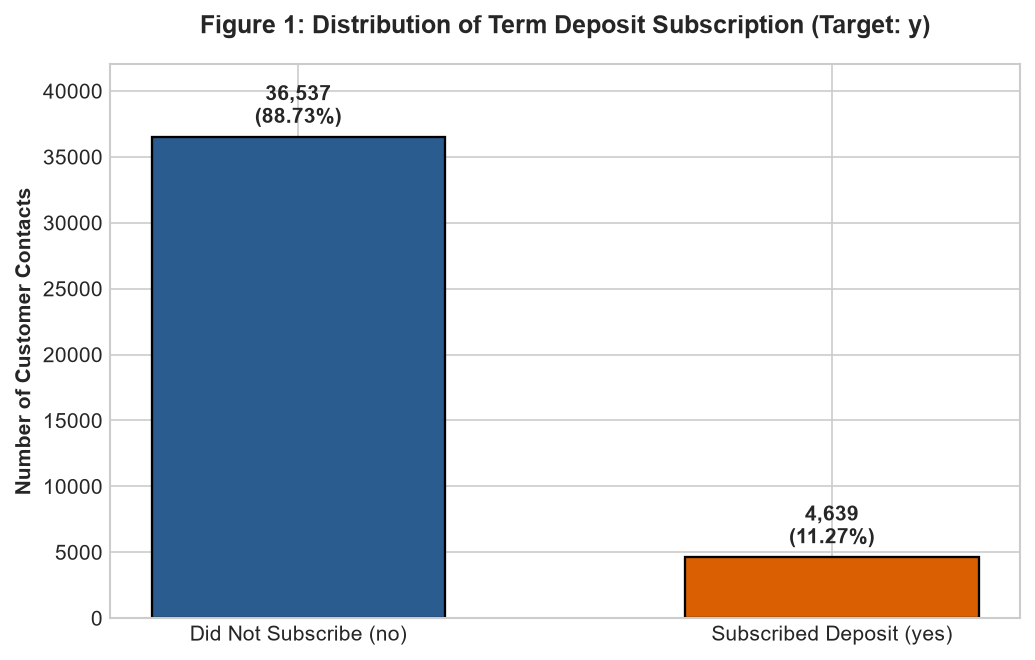

Figure 1 saved to: d:\EDA\figures\fig01_target_distribution.png
Class imbalance ratio: 7.88 : 1


In [7]:
# Figure 1: Target Variable Distribution
y_counts = df['y'].value_counts()
y_pcts = df['y'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(['Did Not Subscribe (no)', 'Subscribed Deposit (yes)'], y_counts.values, 
              color=['#2b5c8f', '#d95f02'], width=0.55, edgecolor='black', linewidth=1.1)

for bar, count, pct in zip(bars, y_counts.values, y_pcts.values):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, height + 600,
            f"{count:,}\n({pct:.2f}%)", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(0, y_counts.max() * 1.15)
ax.set_ylabel("Number of Customer Contacts", fontweight='bold')
ax.set_title("Figure 1: Distribution of Term Deposit Subscription (Target: y)", pad=15)
plt.tight_layout()
fig1_path = os.path.join(FIGURES_DIR, "fig01_target_distribution.png")
plt.savefig(fig1_path)
plt.show()

print(f"Figure 1 saved to: {fig1_path}")
print(f"Class imbalance ratio: {y_counts['no'] / y_counts['yes']:.2f} : 1")


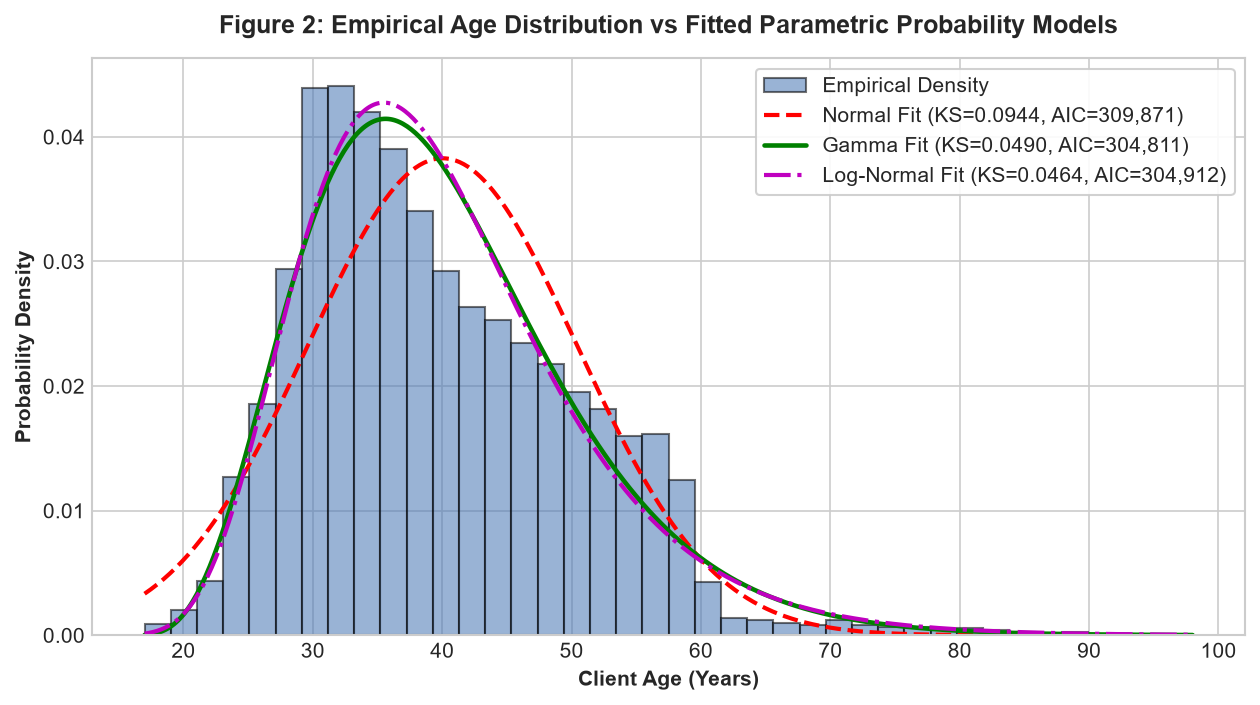

Figure 2 saved to: d:\EDA\figures\fig02_age_distribution_and_fit.png
Age Distribution KS Statistics: Normal=0.0944, Gamma=0.0490, Log-Normal=0.0464


In [8]:
# Figure 2: Distribution of Client Age and Parametric Distribution Fitting
age_vals = df['age'].dropna().values

# Distribution fits
norm_mu, norm_std = stats.norm.fit(age_vals)
gamma_a, gamma_loc, gamma_scale = stats.gamma.fit(age_vals)
lognorm_s, lognorm_loc, lognorm_scale = stats.lognorm.fit(age_vals)

# KS tests
ks_age_norm = stats.kstest(age_vals, 'norm', args=(norm_mu, norm_std))
ks_age_gamma = stats.kstest(age_vals, 'gamma', args=(gamma_a, gamma_loc, gamma_scale))
ks_age_lognorm = stats.kstest(age_vals, 'lognorm', args=(lognorm_s, lognorm_loc, lognorm_scale))

# AIC calculation function
def calc_aic(log_lik, k):
    return 2 * k - 2 * log_lik

ll_age_norm = np.sum(stats.norm.logpdf(age_vals, norm_mu, norm_std))
ll_age_gamma = np.sum(stats.gamma.logpdf(age_vals, gamma_a, gamma_loc, gamma_scale))
ll_age_lognorm = np.sum(stats.lognorm.logpdf(age_vals, lognorm_s, lognorm_loc, lognorm_scale))

aic_age_norm = calc_aic(ll_age_norm, 2)
aic_age_gamma = calc_aic(ll_age_gamma, 3)
aic_age_lognorm = calc_aic(ll_age_lognorm, 3)

# Plotting
fig, ax = plt.subplots(figsize=(8.5, 4.8))
count, bins, _ = ax.hist(age_vals, bins=40, density=True, alpha=0.55, color='#4575b4', 
                         edgecolor='black', label='Empirical Density')
x_grid = np.linspace(age_vals.min(), age_vals.max(), 500)

ax.plot(x_grid, stats.norm.pdf(x_grid, norm_mu, norm_std), 
        'r--', linewidth=2.0, label=f'Normal Fit (KS={ks_age_norm.statistic:.4f}, AIC={aic_age_norm:,.0f})')
ax.plot(x_grid, stats.gamma.pdf(x_grid, gamma_a, gamma_loc, gamma_scale), 
        'g-', linewidth=2.2, label=f'Gamma Fit (KS={ks_age_gamma.statistic:.4f}, AIC={aic_age_gamma:,.0f})')
ax.plot(x_grid, stats.lognorm.pdf(x_grid, lognorm_s, lognorm_loc, lognorm_scale), 
        'm-.', linewidth=2.0, label=f'Log-Normal Fit (KS={ks_age_lognorm.statistic:.4f}, AIC={aic_age_lognorm:,.0f})')

ax.set_xlabel("Client Age (Years)", fontweight='bold')
ax.set_ylabel("Probability Density", fontweight='bold')
ax.set_title("Figure 2: Empirical Age Distribution vs Fitted Parametric Probability Models", pad=12)
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
fig2_path = os.path.join(FIGURES_DIR, "fig02_age_distribution_and_fit.png")
plt.savefig(fig2_path)
plt.show()

print(f"Figure 2 saved to: {fig2_path}")
print(f"Age Distribution KS Statistics: Normal={ks_age_norm.statistic:.4f}, Gamma={ks_age_gamma.statistic:.4f}, Log-Normal={ks_age_lognorm.statistic:.4f}")


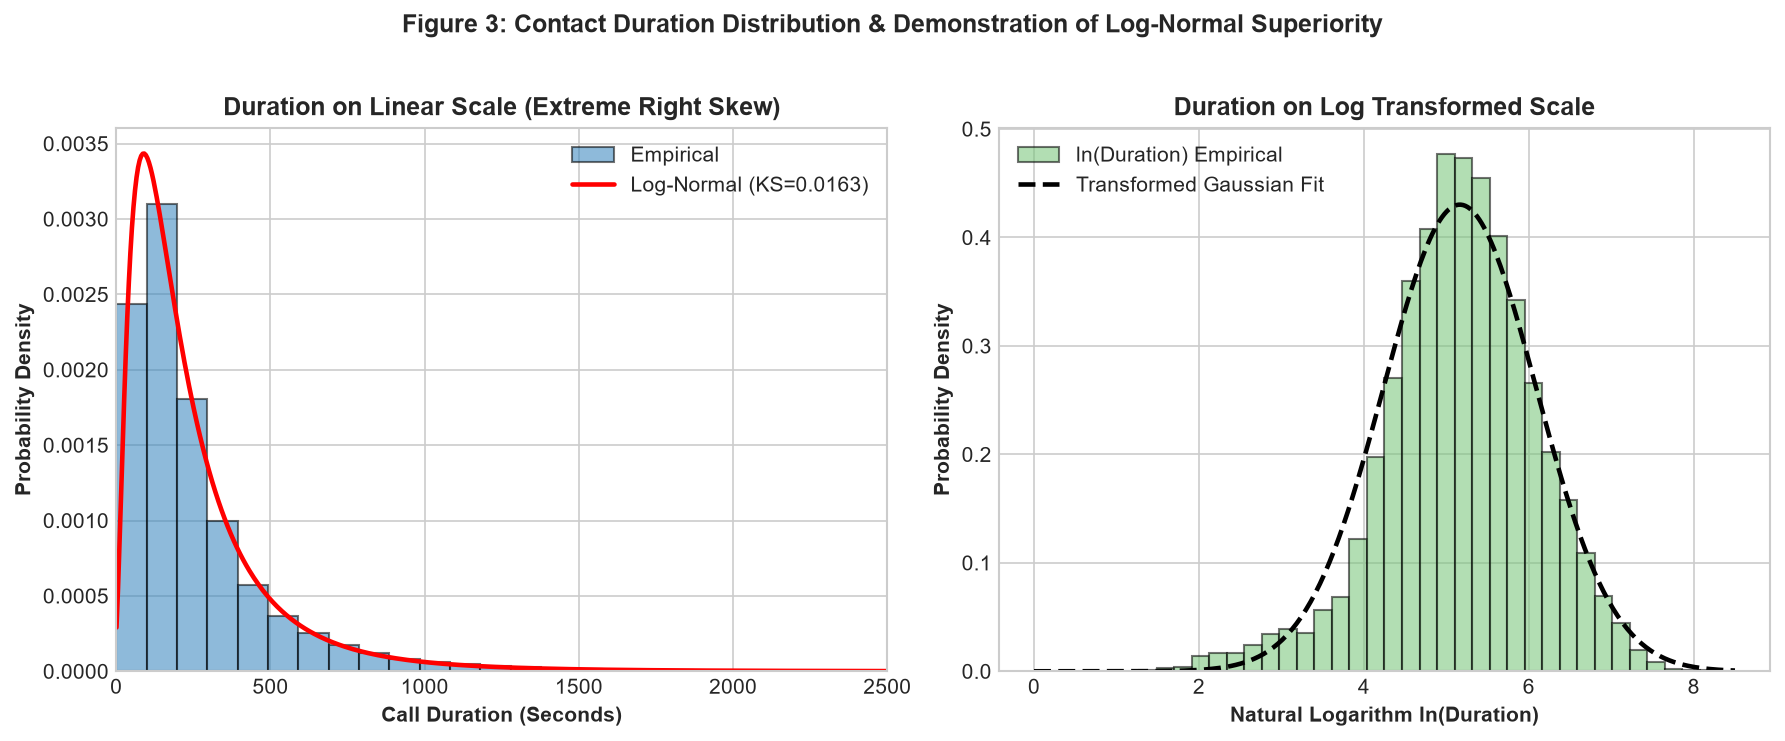

Figure 3 saved to: d:\EDA\figures\fig03_duration_lognormal_fit.png
Duration KS: Normal=0.1695 vs Log-Normal=0.0163 (Substantial improvement!)


In [9]:
# Figure 3: Call Duration Empirical Distribution vs Log-Normal Fit
dur_vals = df['duration'][df['duration'] > 0].values

dur_mu, dur_std = stats.norm.fit(dur_vals)
dur_s, dur_loc, dur_scale = stats.lognorm.fit(dur_vals)

ks_dur_norm = stats.kstest(dur_vals, 'norm', args=(dur_mu, dur_std))
ks_dur_lognorm = stats.kstest(dur_vals, 'lognorm', args=(dur_s, dur_loc, dur_scale))

ll_dur_norm = np.sum(stats.norm.logpdf(dur_vals, dur_mu, dur_std))
ll_dur_lognorm = np.sum(stats.lognorm.logpdf(dur_vals, dur_s, dur_loc, dur_scale))
aic_dur_norm = calc_aic(ll_dur_norm, 2)
aic_dur_lognorm = calc_aic(ll_dur_lognorm, 3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Linear scale
ax1.hist(dur_vals, bins=50, density=True, alpha=0.55, color='#3182bd', edgecolor='black', label='Empirical')
x_dur = np.linspace(dur_vals.min(), 2500, 500)
ax1.plot(x_dur, stats.lognorm.pdf(x_dur, dur_s, dur_loc, dur_scale), 'r-', linewidth=2.2, 
         label=f'Log-Normal (KS={ks_dur_lognorm.statistic:.4f})')
ax1.set_xlabel("Call Duration (Seconds)", fontweight='bold')
ax1.set_ylabel("Probability Density", fontweight='bold')
ax1.set_title("Duration on Linear Scale (Extreme Right Skew)", fontweight='bold')
ax1.set_xlim(0, 2500)
ax1.legend()

# Log scale
log_dur = np.log(dur_vals)
log_mu, log_std = stats.norm.fit(log_dur)
ax2.hist(log_dur, bins=40, density=True, alpha=0.55, color='#74c476', edgecolor='black', label='ln(Duration) Empirical')
x_log = np.linspace(log_dur.min(), log_dur.max(), 300)
ax2.plot(x_log, stats.norm.pdf(x_log, log_mu, log_std), 'k--', linewidth=2.2, label=f'Transformed Gaussian Fit')
ax2.set_xlabel("Natural Logarithm ln(Duration)", fontweight='bold')
ax2.set_ylabel("Probability Density", fontweight='bold')
ax2.set_title("Duration on Log Transformed Scale", fontweight='bold')
ax2.legend()

fig.suptitle("Figure 3: Contact Duration Distribution & Demonstration of Log-Normal Superiority", fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
fig3_path = os.path.join(FIGURES_DIR, "fig03_duration_lognormal_fit.png")
plt.savefig(fig3_path)
plt.show()

print(f"Figure 3 saved to: {fig3_path}")
print(f"Duration KS: Normal={ks_dur_norm.statistic:.4f} vs Log-Normal={ks_dur_lognorm.statistic:.4f} (Substantial improvement!)")


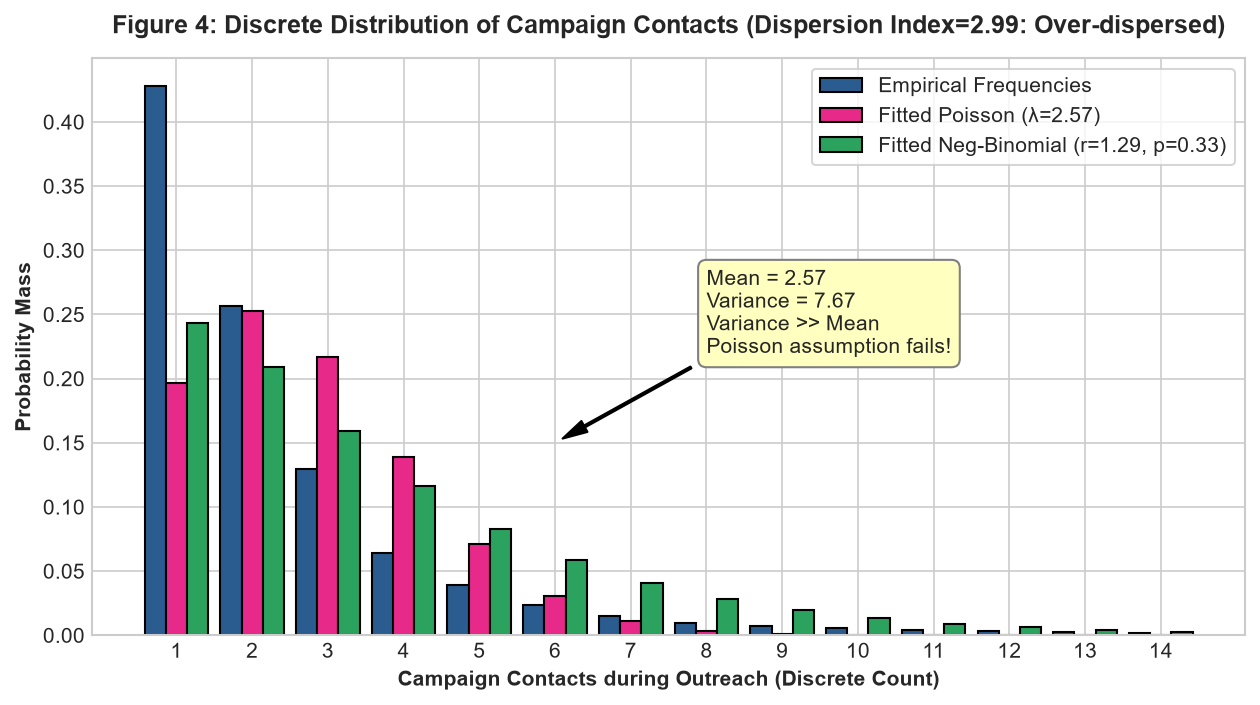

Figure 4 saved to: d:\EDA\figures\fig04_discrete_distribution_campaign.png
Campaign Discrete Distribution: Mean = 2.5679, Variance = 7.6745, Index of Dispersion = 2.9886


In [10]:
# Figure 4: Discrete Probability Modeling on Campaign Contacts & Over-dispersion Analysis
camp_vals = df['campaign'].values
camp_mean = float(np.mean(camp_vals))
camp_var = float(np.var(camp_vals))
dispersion_index = camp_var / camp_mean

# Fitting Poisson model
poisson_k = np.arange(1, 15)
poisson_pmf = stats.poisson.pmf(poisson_k, mu=camp_mean)

# Empirical counts up to 14
emp_freqs = pd.Series(camp_vals).value_counts(normalize=True).sort_index()
emp_pmf = [emp_freqs.get(k, 0.0) for k in poisson_k]

# Fitting Negative Binomial
# Method of moments for NB: p = mean / var, r = mean^2 / (var - mean)
nb_p = camp_mean / camp_var
nb_r = (camp_mean ** 2) / (camp_var - camp_mean)
nb_pmf = stats.nbinom.pmf(poisson_k - 1, nb_r, nb_p)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
x_idx = np.arange(len(poisson_k))
width = 0.28

ax.bar(x_idx - width, emp_pmf, width, label='Empirical Frequencies', color='#2b5c8f', edgecolor='black')
ax.bar(x_idx, poisson_pmf, width, label=f'Fitted Poisson (λ={camp_mean:.2f})', color='#e7298a', edgecolor='black')
ax.bar(x_idx + width, nb_pmf, width, label=f'Fitted Neg-Binomial (r={nb_r:.2f}, p={nb_p:.2f})', color='#2ca25f', edgecolor='black')

ax.set_xticks(x_idx)
ax.set_xticklabels(poisson_k)
ax.set_xlabel("Campaign Contacts during Outreach (Discrete Count)", fontweight='bold')
ax.set_ylabel("Probability Mass", fontweight='bold')
ax.set_title(f"Figure 4: Discrete Distribution of Campaign Contacts (Dispersion Index={dispersion_index:.2f}: Over-dispersed)", pad=12)
ax.legend(frameon=True, facecolor='white')

# Annotation explaining over-dispersion
ax.annotate(f"Mean = {camp_mean:.2f}\nVariance = {camp_var:.2f}\nVariance >> Mean\nPoisson assumption fails!",
            xy=(5, 0.15), xytext=(7, 0.22),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
            bbox=dict(boxstyle="round,pad=0.4", fc="#ffffbf", ec="gray", lw=1))

plt.tight_layout()
fig4_path = os.path.join(FIGURES_DIR, "fig04_discrete_distribution_campaign.png")
plt.savefig(fig4_path)
plt.show()

print(f"Figure 4 saved to: {fig4_path}")
print(f"Campaign Discrete Distribution: Mean = {camp_mean:.4f}, Variance = {camp_var:.4f}, Index of Dispersion = {dispersion_index:.4f}")


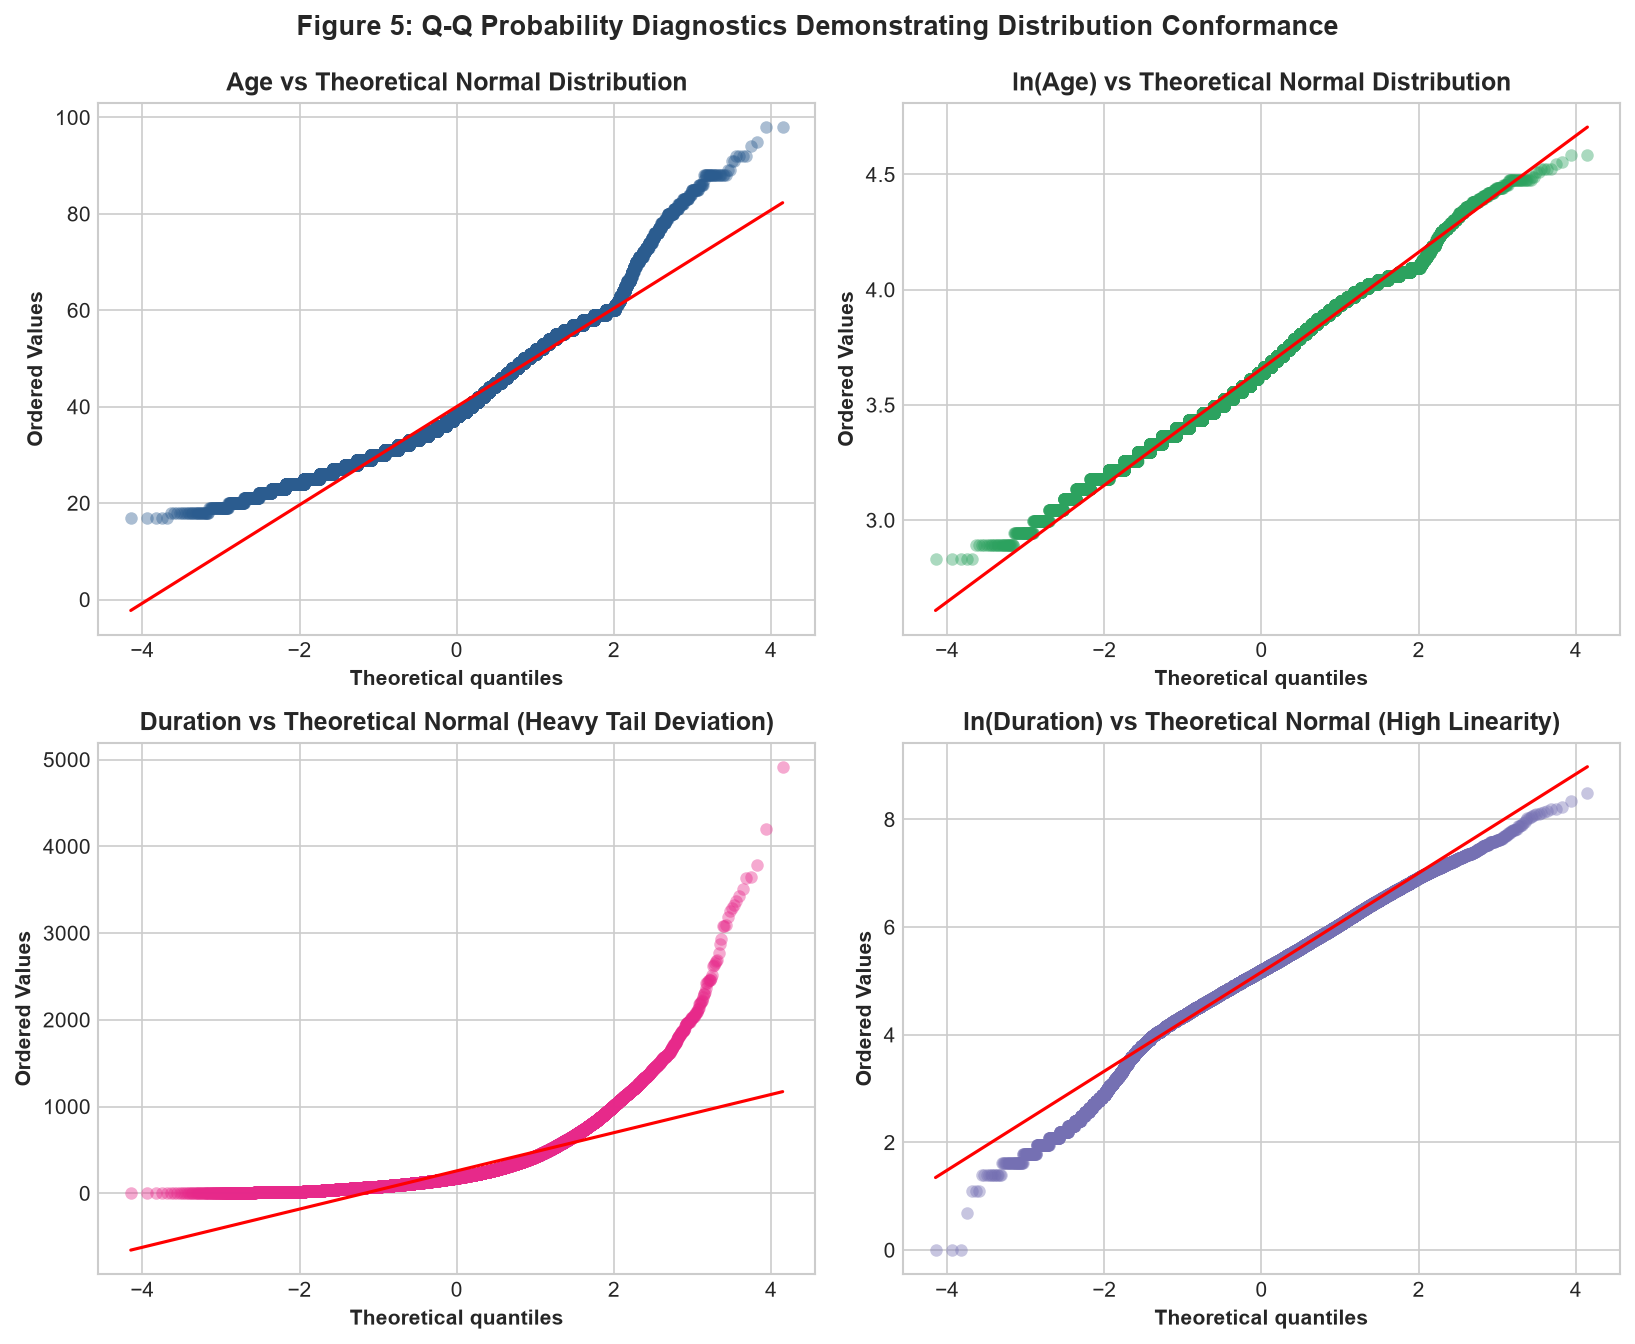

Figure 5 saved to: d:\EDA\figures\fig05_qq_plots_comparison.png


In [11]:
# Figure 5: Quantile-Quantile (Q-Q) Diagnostics for Continuous Variables
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

# Age vs Normal
stats.probplot(age_vals, dist="norm", plot=axes[0, 0])
axes[0, 0].set_title("Age vs Theoretical Normal Distribution", fontweight='bold')
axes[0, 0].get_lines()[0].set_markerfacecolor('#2b5c8f')
axes[0, 0].get_lines()[0].set_markeredgecolor('none')
axes[0, 0].get_lines()[0].set_alpha(0.4)
axes[0, 0].get_lines()[1].set_color('red')

# Age vs Log-normal
stats.probplot(np.log(age_vals), dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("ln(Age) vs Theoretical Normal Distribution", fontweight='bold')
axes[0, 1].get_lines()[0].set_markerfacecolor('#2ca25f')
axes[0, 1].get_lines()[0].set_markeredgecolor('none')
axes[0, 1].get_lines()[0].set_alpha(0.4)
axes[0, 1].get_lines()[1].set_color('red')

# Duration vs Normal
stats.probplot(dur_vals, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Duration vs Theoretical Normal (Heavy Tail Deviation)", fontweight='bold')
axes[1, 0].get_lines()[0].set_markerfacecolor('#e7298a')
axes[1, 0].get_lines()[0].set_markeredgecolor('none')
axes[1, 0].get_lines()[0].set_alpha(0.4)
axes[1, 0].get_lines()[1].set_color('red')

# Duration vs Log-normal
stats.probplot(log_dur, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("ln(Duration) vs Theoretical Normal (High Linearity)", fontweight='bold')
axes[1, 1].get_lines()[0].set_markerfacecolor('#7570b3')
axes[1, 1].get_lines()[0].set_markeredgecolor('none')
axes[1, 1].get_lines()[0].set_alpha(0.4)
axes[1, 1].get_lines()[1].set_color('red')

fig.suptitle("Figure 5: Q-Q Probability Diagnostics Demonstrating Distribution Conformance", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
fig5_path = os.path.join(FIGURES_DIR, "fig05_qq_plots_comparison.png")
plt.savefig(fig5_path)
plt.show()

print(f"Figure 5 saved to: {fig5_path}")


IQR Outlier Summary Table:
         Feature    Q25    Q75    IQR  Lower Bound  Upper Bound  \
0            age   32.0   47.0   15.0         9.50        69.50   
1       duration  102.0  319.0  217.0      -223.50       644.50   
2       campaign    1.0    3.0    2.0        -2.00         6.00   
3  cons.conf.idx  -42.7  -36.4    6.3       -52.15       -26.95   

   Outliers Count  Outliers (%)  
0             468          1.14  
1            2963          7.20  
2            2406          5.84  
3             446          1.08  


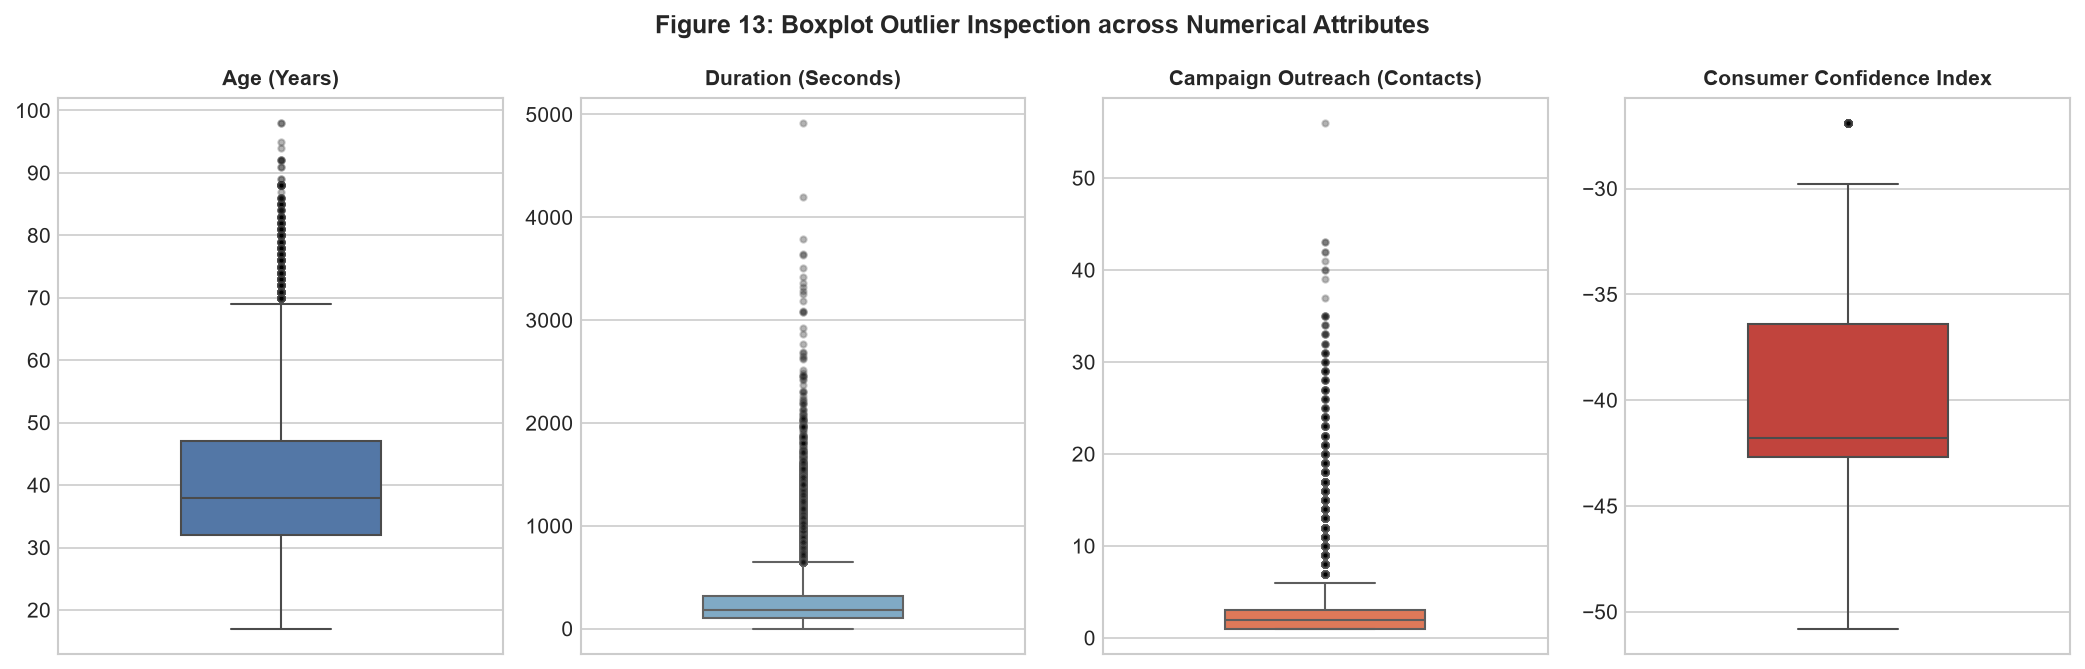

Figure 13 saved to: d:\EDA\figures\fig13_outliers_boxplots.png


In [12]:
# Figure 13: Multi-Panel Outlier Exploration via Interquartile Range (IQR) Boxplots
box_cols = ['age', 'duration', 'campaign', 'cons.conf.idx']
box_labels = ['Age (Years)', 'Duration (Seconds)', 'Campaign Outreach (Contacts)', 'Consumer Confidence Index']

iqr_summary = []
for col, lbl in zip(box_cols, box_labels):
    q25 = df[col].quantile(0.25)
    q75 = df[col].quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr
    outliers_cnt = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    iqr_summary.append({
        "Feature": col,
        "Q25": round(float(q25), 2),
        "Q75": round(float(q75), 2),
        "IQR": round(float(iqr), 2),
        "Lower Bound": round(float(lower_bound), 2),
        "Upper Bound": round(float(upper_bound), 2),
        "Outliers Count": int(outliers_cnt),
        "Outliers (%)": round(float(outliers_cnt / len(df) * 100), 2)
    })

iqr_df = pd.DataFrame(iqr_summary)
print("IQR Outlier Summary Table:")
print(iqr_df)

fig, axes = plt.subplots(1, 4, figsize=(14, 4.5))
palette = ['#4575b4', '#74add1', '#f46d43', '#d73027']

for i, (col, lbl) in enumerate(zip(box_cols, box_labels)):
    sns.boxplot(y=df[col], ax=axes[i], color=palette[i], width=0.45,
                flierprops=dict(marker='o', markersize=3, alpha=0.3, markerfacecolor='black'))
    axes[i].set_title(lbl, fontweight='bold', fontsize=10)
    axes[i].set_ylabel("")

fig.suptitle("Figure 13: Boxplot Outlier Inspection across Numerical Attributes", fontsize=12, fontweight='bold', y=0.98)
plt.tight_layout()
fig13_path = os.path.join(FIGURES_DIR, "fig13_outliers_boxplots.png")
plt.savefig(fig13_path)
plt.show()

print(f"Figure 13 saved to: {fig13_path}")


## 7. Bivariate & Multivariate Statistical Analysis (CO4)
We evaluate relationships between predictor attributes and the target subscription variable using:
- **Grouped Subscription Rates by Demographics**: Conversion rates across job categories, education, and marital status.
- **Hypothesis Testing**:
  - Pearson's Chi-Square Test of Independence ($\chi^2$) and Cramer's V effect size for categorical variables.
  - Mann-Whitney U non-parametric two-sided test and Rank-biserial effect sizes for continuous variables.
- **Multivariate Correlation Heatmaps**: Pearson linear and Spearman rank-order correlation matrices.
- **Macroeconomic Interaction Analysis**: Euribor 3-Month rate versus contact duration, and interaction heatmaps.


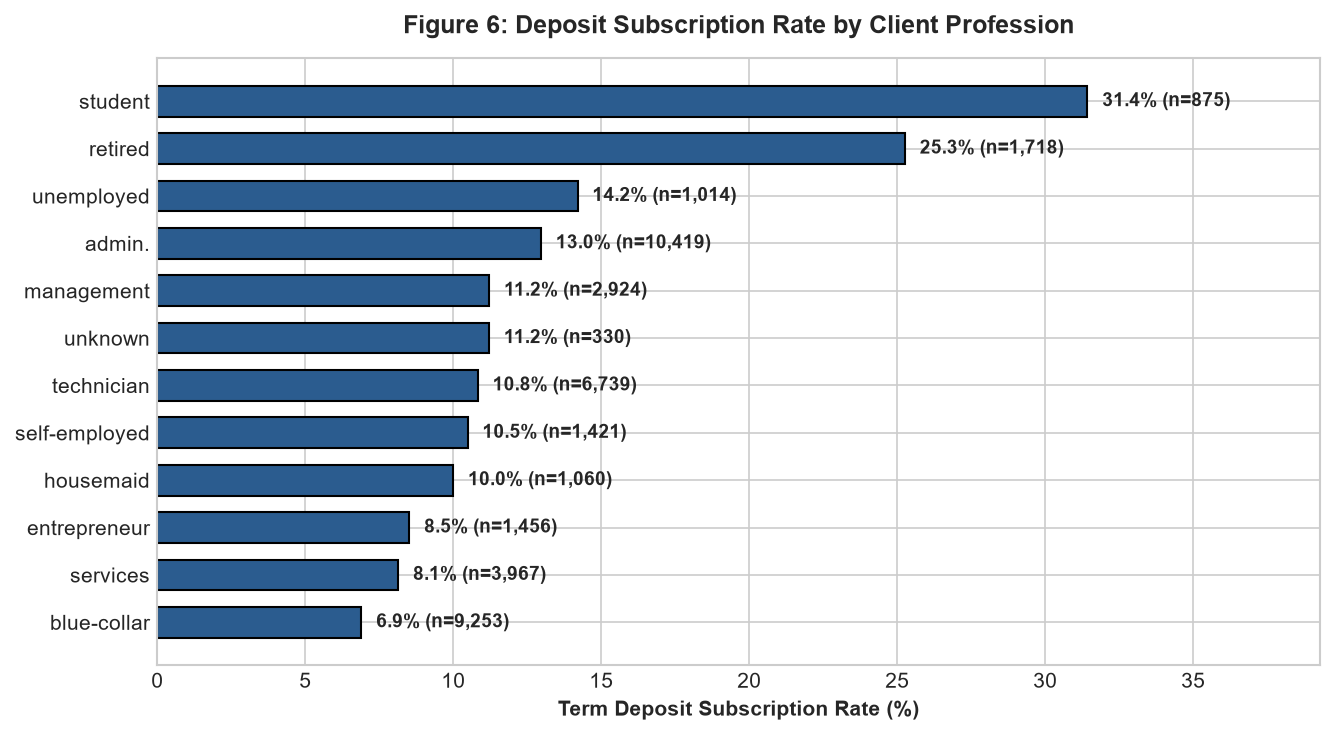

Figure 6 saved to: d:\EDA\figures\fig06_job_vs_deposit.png
Highest conversion jobs: Student (31.43%) and Retired (25.26%)
Lowest conversion jobs: Blue-collar (6.90%) and Services (8.14%)


In [13]:
# Figure 6: Subscription Rate across Job Categories
job_grouped = df.groupby('job')['y'].agg(
    Total='count',
    Subscribed=lambda x: (x == 'yes').sum(),
    Rate=lambda x: (x == 'yes').mean() * 100
).sort_values(by='Rate', ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(job_grouped.index, job_grouped['Rate'], color='#2b5c8f', edgecolor='black', height=0.65)

for bar, rate, tot in zip(bars, job_grouped['Rate'], job_grouped['Total']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2.0,
            f"{rate:.1f}% (n={tot:,})", va='center', fontsize=9, fontweight='bold')

ax.set_xlim(0, job_grouped['Rate'].max() * 1.25)
ax.set_xlabel("Term Deposit Subscription Rate (%)", fontweight='bold')
ax.set_title("Figure 6: Deposit Subscription Rate by Client Profession", pad=12)
ax.invert_yaxis()
plt.tight_layout()
fig6_path = os.path.join(FIGURES_DIR, "fig06_job_vs_deposit.png")
plt.savefig(fig6_path)
plt.show()

print(f"Figure 6 saved to: {fig6_path}")
print(f"Highest conversion jobs: Student ({job_grouped.loc['student', 'Rate']:.2f}%) and Retired ({job_grouped.loc['retired', 'Rate']:.2f}%)")
print(f"Lowest conversion jobs: Blue-collar ({job_grouped.loc['blue-collar', 'Rate']:.2f}%) and Services ({job_grouped.loc['services', 'Rate']:.2f}%)")


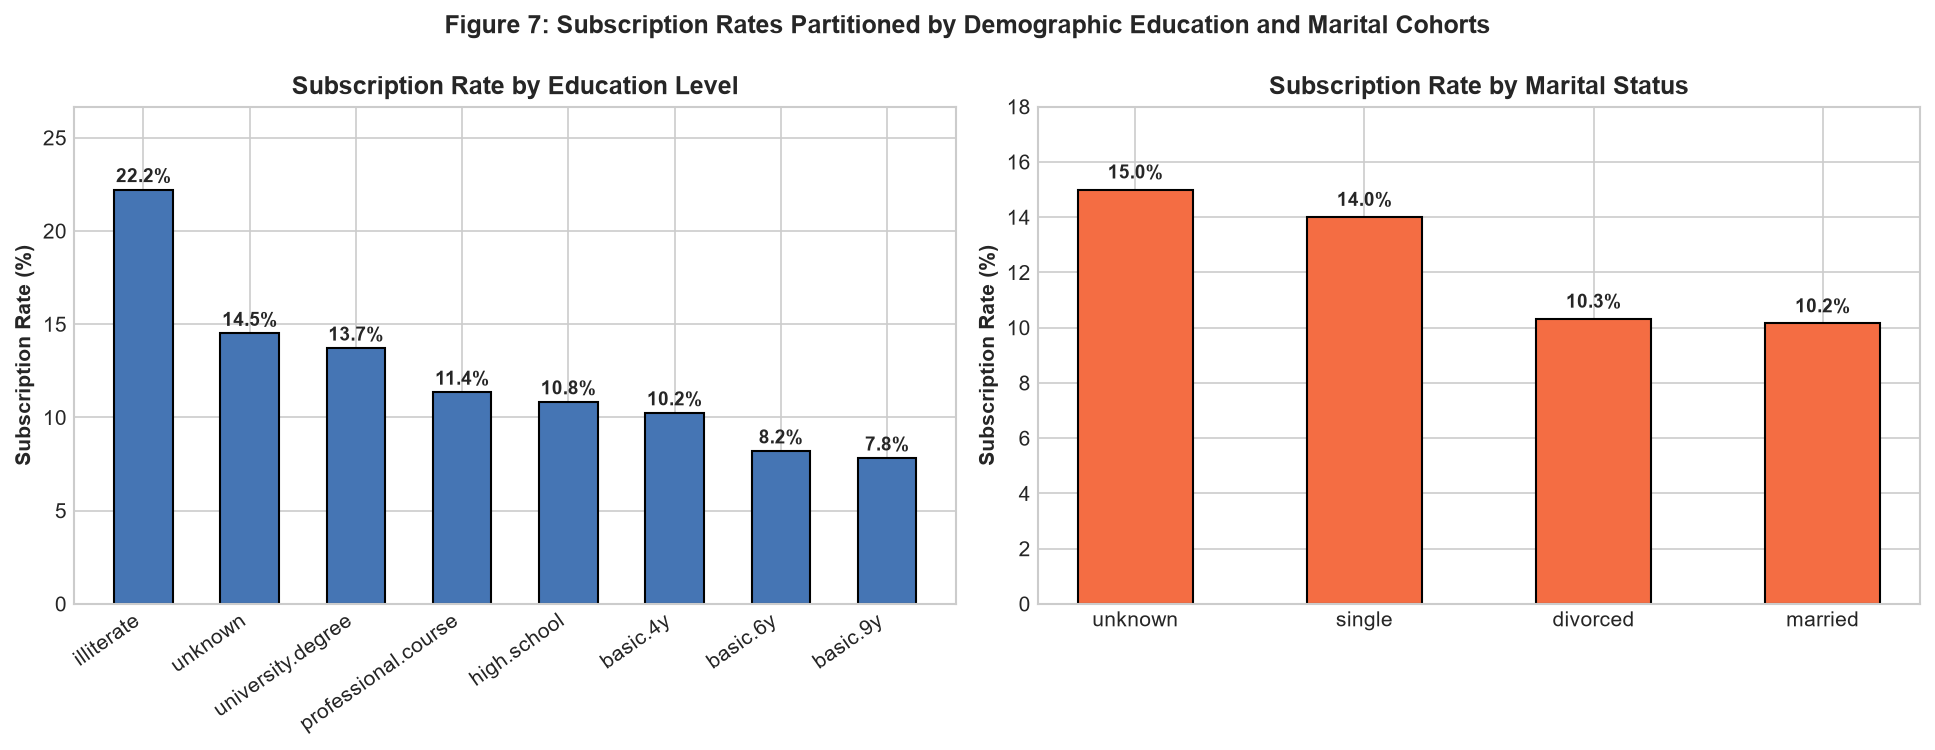

Figure 7 saved to: d:\EDA\figures\fig07_education_marital_rates.png


In [14]:
# Figure 7: Conversion Rates Grouped by Education Level and Marital Status
edu_grouped = df.groupby('education')['y'].apply(lambda x: (x == 'yes').mean() * 100).sort_values(ascending=False)
mar_grouped = df.groupby('marital')['y'].apply(lambda x: (x == 'yes').mean() * 100).sort_values(ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Education
ax1.bar(edu_grouped.index, edu_grouped.values, color='#4575b4', edgecolor='black', width=0.55)
for i, v in enumerate(edu_grouped.values):
    ax1.text(i, v + 0.4, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=9)
ax1.set_xticklabels(edu_grouped.index, rotation=35, ha='right')
ax1.set_ylabel("Subscription Rate (%)", fontweight='bold')
ax1.set_title("Subscription Rate by Education Level", fontweight='bold')
ax1.set_ylim(0, edu_grouped.max() * 1.2)

# Marital
ax2.bar(mar_grouped.index, mar_grouped.values, color='#f46d43', edgecolor='black', width=0.5)
for i, v in enumerate(mar_grouped.values):
    ax2.text(i, v + 0.4, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=9)
ax2.set_xticklabels(mar_grouped.index, rotation=0)
ax2.set_ylabel("Subscription Rate (%)", fontweight='bold')
ax2.set_title("Subscription Rate by Marital Status", fontweight='bold')
ax2.set_ylim(0, mar_grouped.max() * 1.2)

fig.suptitle("Figure 7: Subscription Rates Partitioned by Demographic Education and Marital Cohorts", fontsize=12, fontweight='bold', y=0.99)
plt.tight_layout()
fig7_path = os.path.join(FIGURES_DIR, "fig07_education_marital_rates.png")
plt.savefig(fig7_path)
plt.show()

print(f"Figure 7 saved to: {fig7_path}")


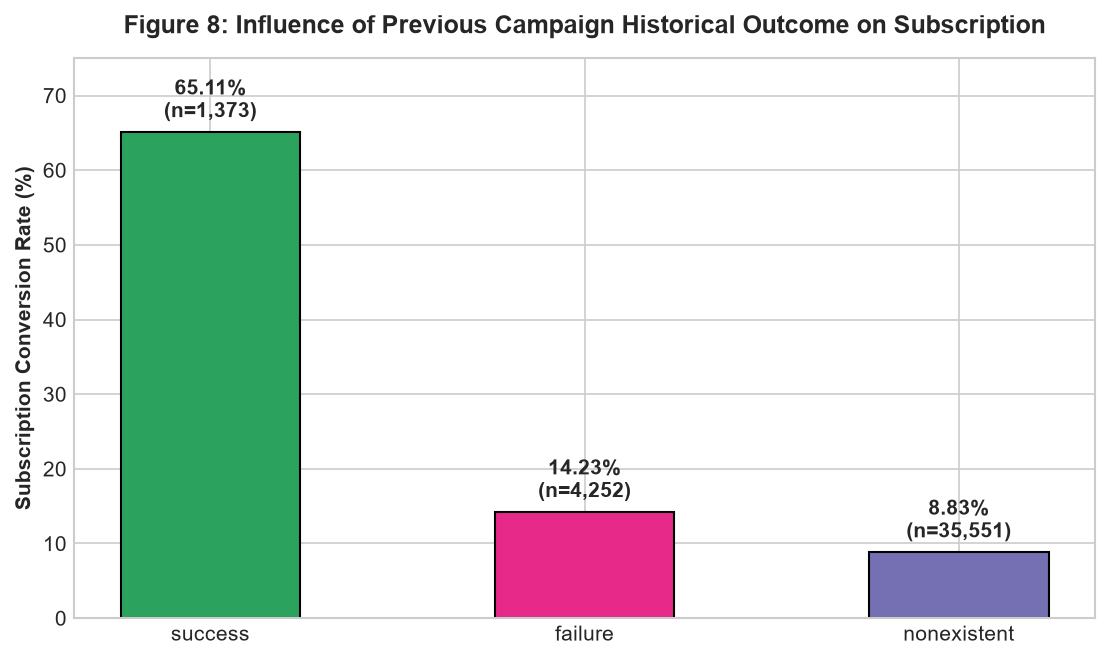

Figure 8 saved to: d:\EDA\figures\fig08_previous_outcome_effect.png
Success in past campaign yielded conversion rate of 65.11% compared to 8.83% for fresh clients.


In [15]:
# Figure 8: Impact of Previous Campaign Outcome (poutcome) on Subscription
pout_summary = df.groupby('poutcome')['y'].agg(
    Total='count',
    Subscribed=lambda x: (x == 'yes').sum(),
    Rate=lambda x: (x == 'yes').mean() * 100
).sort_values(by='Rate', ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(pout_summary.index, pout_summary['Rate'], color=['#2ca25f', '#e7298a', '#7570b3'], 
              edgecolor='black', width=0.48)

for bar, rate, tot in zip(bars, pout_summary['Rate'], pout_summary['Total']):
    ax.text(bar.get_x() + bar.get_width() / 2.0, bar.get_height() + 1.2,
            f"{rate:.2f}%\n(n={tot:,})", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(0, 75)
ax.set_ylabel("Subscription Conversion Rate (%)", fontweight='bold')
ax.set_title("Figure 8: Influence of Previous Campaign Historical Outcome on Subscription", pad=12)
plt.tight_layout()
fig8_path = os.path.join(FIGURES_DIR, "fig08_previous_outcome_effect.png")
plt.savefig(fig8_path)
plt.show()

print(f"Figure 8 saved to: {fig8_path}")
print(f"Success in past campaign yielded conversion rate of {pout_summary.loc['success', 'Rate']:.2f}% compared to {pout_summary.loc['nonexistent', 'Rate']:.2f}% for fresh clients.")


In [16]:
# Chi-Square Test of Independence & Cramer's V Association Metric
def calculate_cramers_v(contingency_tab):
    chi2 = stats.chi2_contingency(contingency_tab)[0]
    n = contingency_tab.sum()
    phi2 = chi2 / n
    r, k = contingency_tab.shape
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    denom = min((kcorr - 1), (rcorr - 1))
    if denom <= 0:
        return 0.0
    return np.sqrt(phi2corr / denom)

categorical_test_cols = ['poutcome', 'pdays_group', 'contact', 'month', 'job', 
                         'default', 'education', 'age_group', 'marital', 'day_of_week', 'housing', 'loan']

chi2_table = []
for col in categorical_test_cols:
    ct = pd.crosstab(df[col], df['y']).values
    chi2_val, p_val, dof, _ = stats.chi2_contingency(ct)
    cv_val = calculate_cramers_v(ct)
    chi2_table.append({
        "Categorical Feature": col,
        "Chi-Square (χ²)": round(float(chi2_val), 2),
        "dof": int(dof),
        "p-value": "< 0.001" if p_val < 0.001 else f"{p_val:.4f}",
        "Cramer's V": round(float(cv_val), 4),
        "Association Strength": "Moderate to High" if cv_val > 0.25 else ("Low to Moderate" if cv_val > 0.1 else "Negligible")
    })

chi2_results_df = pd.DataFrame(chi2_table).sort_values(by="Cramer's V", ascending=False)
print("Chi-Square Test of Independence & Cramer's V Summary Table:")
print(chi2_results_df.to_string(index=False))


Chi-Square Test of Independence & Cramer's V Summary Table:
Categorical Feature  Chi-Square (χ²)  dof p-value  Cramer's V Association Strength
        pdays_group          4363.14    3 < 0.001      0.3254     Moderate to High
           poutcome          4230.14    2 < 0.001      0.3204     Moderate to High
              month          3103.03    9 < 0.001      0.2741     Moderate to High
          age_group          1295.56    3 < 0.001      0.1772      Low to Moderate
                job           961.74   11 < 0.001      0.1520      Low to Moderate
            contact           862.08    1 < 0.001      0.1446      Low to Moderate
            default           406.56    2 < 0.001      0.0991           Negligible
          education           192.85    7 < 0.001      0.0672           Negligible
            marital           122.96    3 < 0.001      0.0540           Negligible
        day_of_week            26.05    4 < 0.001      0.0231           Negligible
            housing        

In [17]:
# Non-Parametric Mann-Whitney U Test & Effect Sizes for Continuous Variables
continuous_test_cols = ['duration', 'euribor3m', 'nr.employed', 'emp.var.rate', 
                        'cons.price.idx', 'economic_stress_index', 'age', 'campaign_intensity', 'cons.conf.idx']

mwu_summary = []
no_group = df[df['y'] == 'no']
yes_group = df[df['y'] == 'yes']

for col in continuous_test_cols:
    no_vals = no_group[col].dropna().values
    yes_vals = yes_group[col].dropna().values
    u_stat, p_val = stats.mannwhitneyu(yes_vals, no_vals, alternative='two-sided')
    n1 = len(yes_vals)
    n2 = len(no_vals)
    rank_biserial = 1.0 - (2.0 * u_stat) / (n1 * n2)
    mwu_summary.append({
        "Continuous Feature": col,
        "Mean (Did Not Subscribe)": round(float(np.mean(no_vals)), 2),
        "Mean (Subscribed)": round(float(np.mean(yes_vals)), 2),
        "Mann-Whitney U": round(float(u_stat), 0),
        "p-value": "< 0.001" if p_val < 0.001 else f"{p_val:.4f}",
        "Rank-Biserial Effect Size": round(float(rank_biserial), 4),
        "Direction": "Subscribed Higher" if rank_biserial < 0 else "Subscribed Lower"
    })

mwu_results_df = pd.DataFrame(mwu_summary).sort_values(by="Rank-Biserial Effect Size", key=lambda x: abs(x), ascending=False)
print("Mann-Whitney U Test & Effect Size Summary Table:")
print(mwu_results_df.to_string(index=False))


Mann-Whitney U Test & Effect Size Summary Table:
   Continuous Feature  Mean (Did Not Subscribe)  Mean (Subscribed)  Mann-Whitney U p-value  Rank-Biserial Effect Size         Direction
             duration                    220.87             553.26     138721931.0 < 0.001                    -0.6369 Subscribed Higher
          nr.employed                   5176.17            5095.12      42551676.0 < 0.001                     0.4979  Subscribed Lower
            euribor3m                      3.81               2.12      43488310.0 < 0.001                     0.4868  Subscribed Lower
         emp.var.rate                      0.25              -1.23      48017796.0 < 0.001                     0.4334  Subscribed Lower
economic_stress_index                      0.08              -0.62      49690405.0 < 0.001                     0.4137  Subscribed Lower
   campaign_intensity                      2.51               1.73      64699072.0 < 0.001                     0.2366  Subscribed Lower

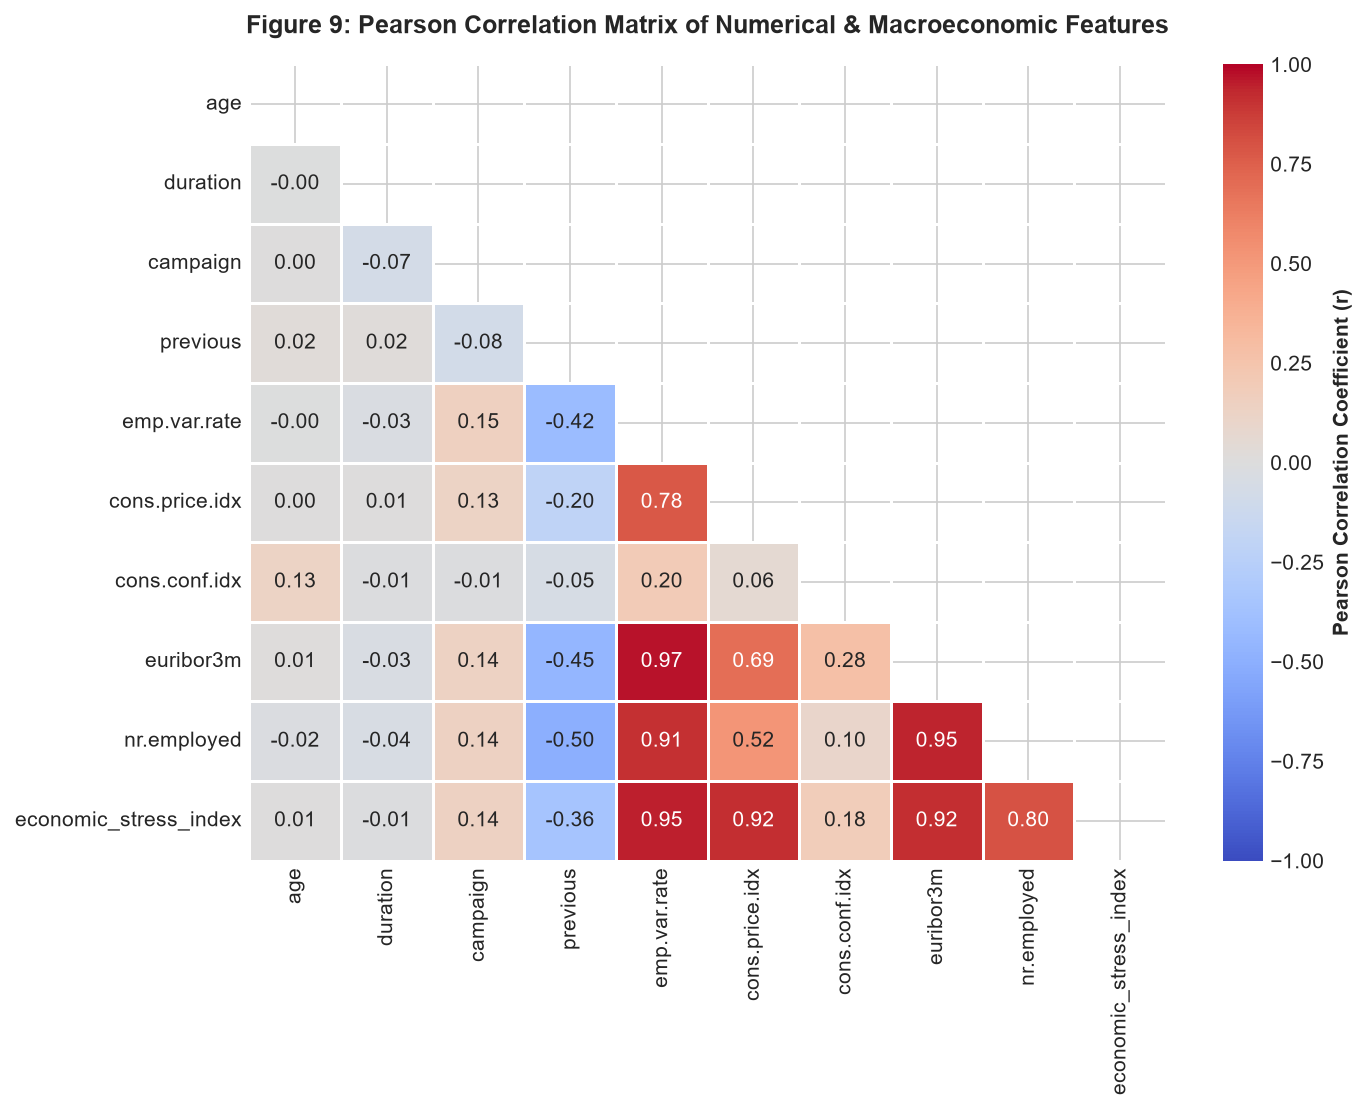

Figure 9 saved to: d:\EDA\figures\fig09_correlation_heatmap.png
Strongest collinear pair: euribor3m and nr.employed (r = 0.95)
emp.var.rate and euribor3m (r = 0.97)


In [18]:
# Figure 9: Correlation Matrix of Numerical and Macroeconomic Predictors
corr_vars = ['age', 'duration', 'campaign', 'previous', 'emp.var.rate', 
             'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'economic_stress_index']
corr_matrix = df[corr_vars].corr(method='pearson')

fig, ax = plt.subplots(figsize=(9.5, 7.5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1,
            cbar_kws={'label': 'Pearson Correlation Coefficient (r)'}, ax=ax, linewidths=0.5)

ax.set_title("Figure 9: Pearson Correlation Matrix of Numerical & Macroeconomic Features", pad=15)
plt.tight_layout()
fig9_path = os.path.join(FIGURES_DIR, "fig09_correlation_heatmap.png")
plt.savefig(fig9_path)
plt.show()

print(f"Figure 9 saved to: {fig9_path}")
print(f"Strongest collinear pair: euribor3m and nr.employed (r = {corr_matrix.loc['euribor3m', 'nr.employed']:.2f})")
print(f"emp.var.rate and euribor3m (r = {corr_matrix.loc['emp.var.rate', 'euribor3m']:.2f})")


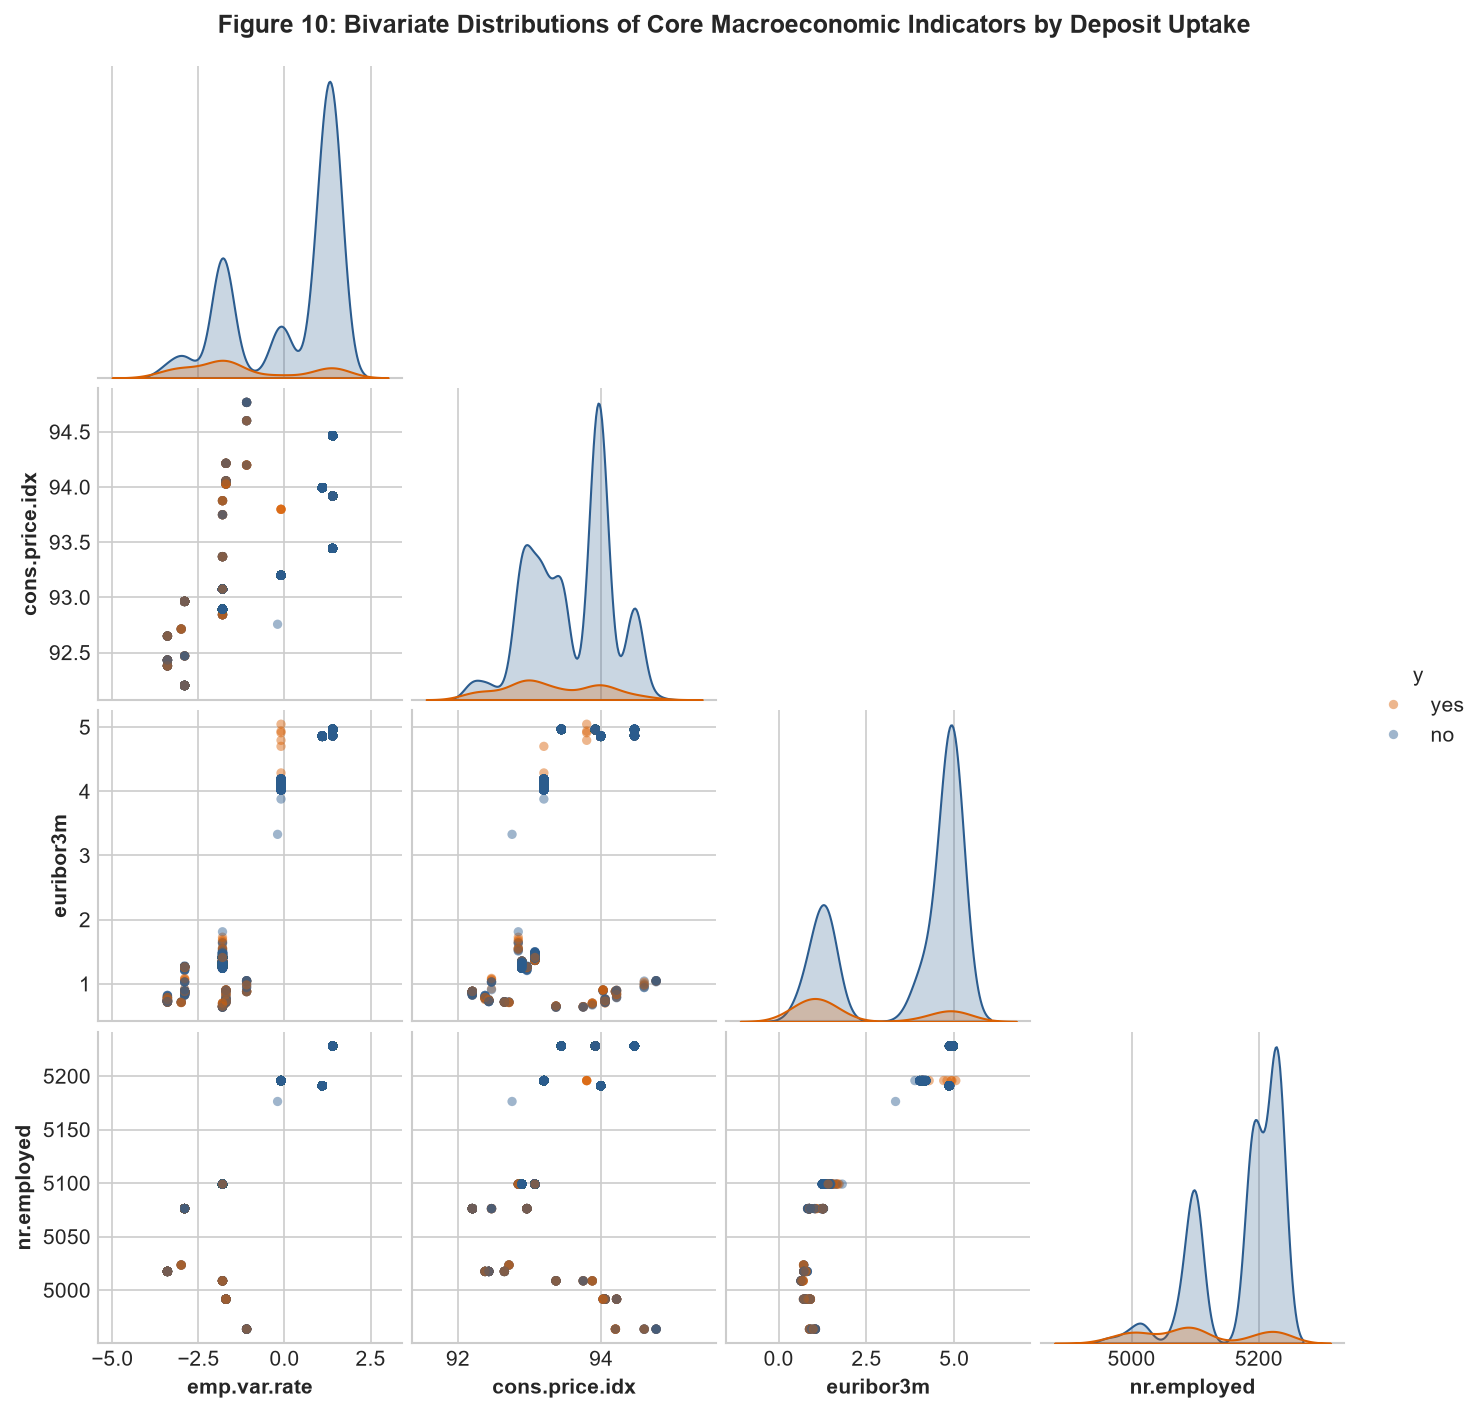

Figure 10 saved to: d:\EDA\figures\fig10_economic_indicators_pairplot.png


In [19]:
# Figure 10: Macroeconomic Bivariate Relationships
eco_vars = ['emp.var.rate', 'cons.price.idx', 'euribor3m', 'nr.employed']
sample_df = df[eco_vars + ['y']].sample(n=2500, random_state=SEED)

g = sns.pairplot(sample_df, hue='y', palette={'no': '#2b5c8f', 'yes': '#d95f02'}, 
                 plot_kws={'alpha': 0.45, 's': 20, 'edgecolor': 'none'},
                 diag_kind='kde', corner=True, height=2.3)
g.fig.suptitle("Figure 10: Bivariate Distributions of Core Macroeconomic Indicators by Deposit Uptake", 
               y=1.02, fontsize=12, fontweight='bold')
fig10_path = os.path.join(FIGURES_DIR, "fig10_economic_indicators_pairplot.png")
g.savefig(fig10_path)
plt.show()

print(f"Figure 10 saved to: {fig10_path}")


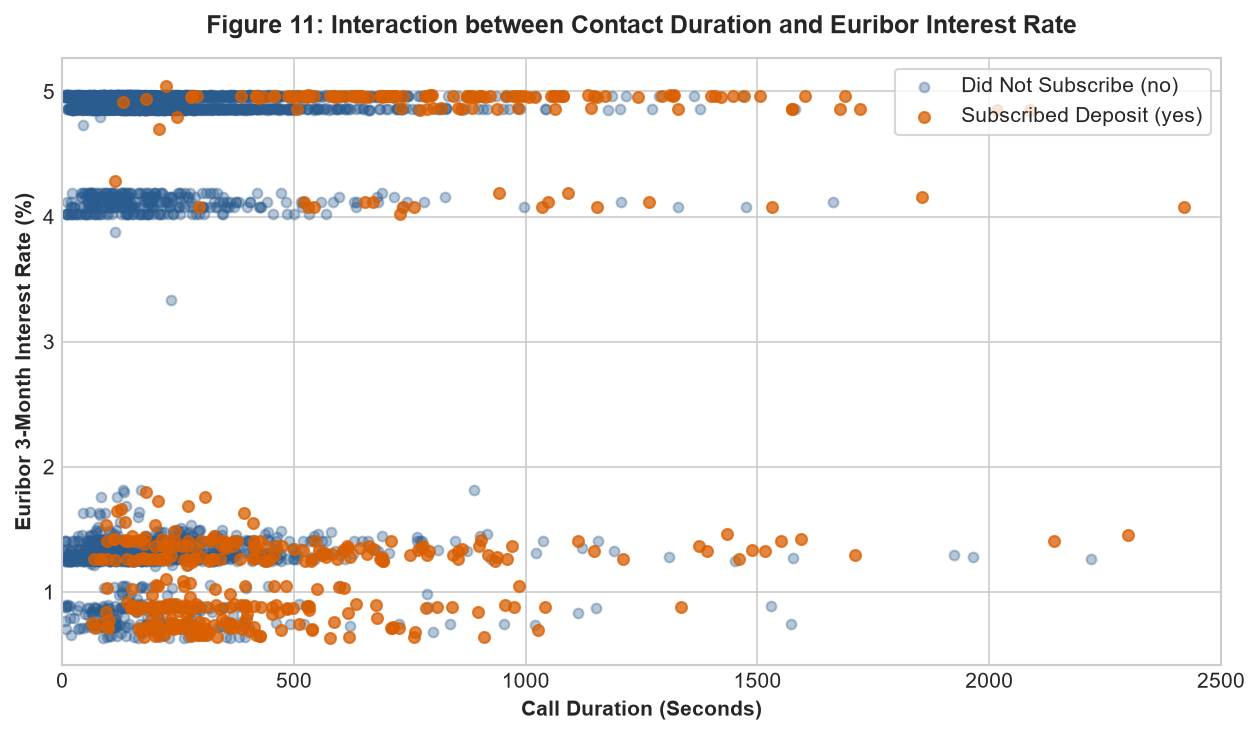

Figure 11 saved to: d:\EDA\figures\fig11_euribor_vs_duration_scatter.png


In [20]:
# Figure 11: Scatter Plot of Euribor 3-Month Rate vs Call Duration
scatter_sample = df.sample(n=4000, random_state=SEED)

fig, ax = plt.subplots(figsize=(8.5, 5))
no_pts = scatter_sample[scatter_sample['y'] == 'no']
yes_pts = scatter_sample[scatter_sample['y'] == 'yes']

ax.scatter(no_pts['duration'], no_pts['euribor3m'], color='#2b5c8f', alpha=0.35, s=22, label='Did Not Subscribe (no)')
ax.scatter(yes_pts['duration'], yes_pts['euribor3m'], color='#d95f02', alpha=0.75, s=28, label='Subscribed Deposit (yes)')

ax.set_xlabel("Call Duration (Seconds)", fontweight='bold')
ax.set_ylabel("Euribor 3-Month Interest Rate (%)", fontweight='bold')
ax.set_title("Figure 11: Interaction between Contact Duration and Euribor Interest Rate", pad=12)
ax.set_xlim(0, 2500)
ax.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
fig11_path = os.path.join(FIGURES_DIR, "fig11_euribor_vs_duration_scatter.png")
plt.savefig(fig11_path)
plt.show()

print(f"Figure 11 saved to: {fig11_path}")


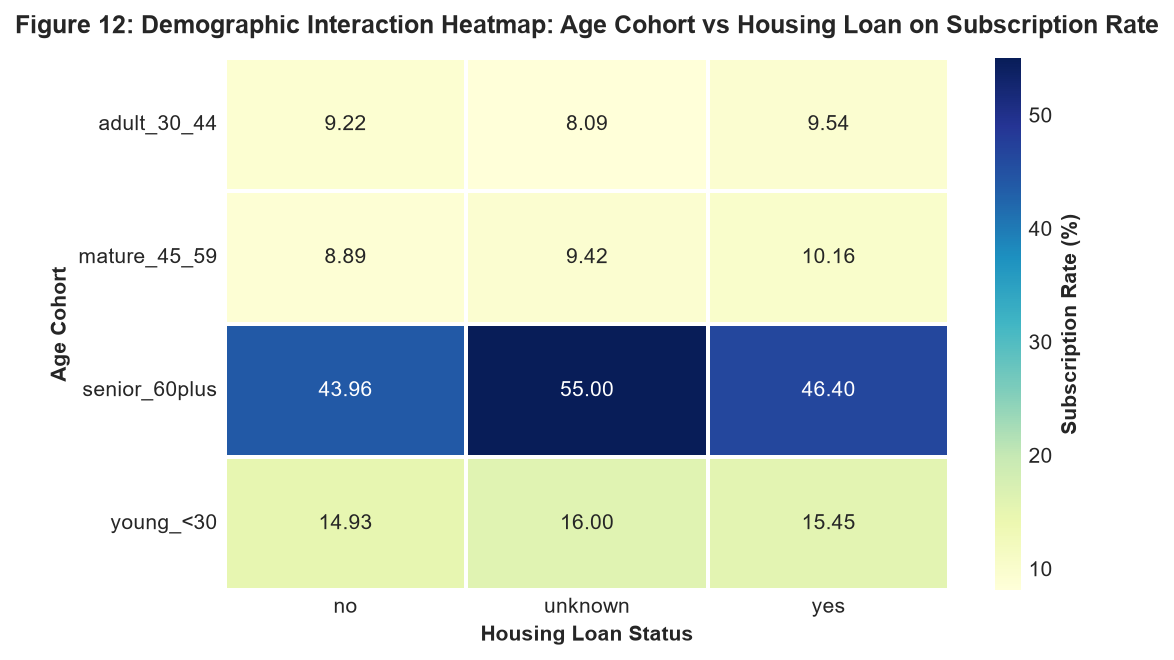

Figure 12 saved to: d:\EDA\figures\fig12_age_group_and_housing_interaction.png


In [21]:
# Figure 12: Interaction Heatmap of Age Group vs Housing Loan on Subscription
interaction_pt = df.pivot_table(index='age_group', columns='housing', values='y', 
                                aggfunc=lambda x: (x == 'yes').mean() * 100)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(interaction_pt, annot=True, fmt=".2f", cmap='YlGnBu', cbar_kws={'label': 'Subscription Rate (%)'},
            ax=ax, linewidths=1.0)

ax.set_xlabel("Housing Loan Status", fontweight='bold')
ax.set_ylabel("Age Cohort", fontweight='bold')
ax.set_title("Figure 12: Demographic Interaction Heatmap: Age Cohort vs Housing Loan on Subscription Rate", pad=12)
plt.tight_layout()
fig12_path = os.path.join(FIGURES_DIR, "fig12_age_group_and_housing_interaction.png")
plt.savefig(fig12_path)
plt.show()

print(f"Figure 12 saved to: {fig12_path}")


## 8. Ben Fry's 7 Stages of Data Visualization & Interactive Chart
To satisfy the pedagogical requirements of Fry's classic visualization paradigm (Acquire, Parse, Filter, Mine, Represent, Refine, Interact), we formulate the 7-stage workflow implementation:

| Stage | Definition | Implementation in this Case Study |
| :--- | :--- | :--- |
| **1. Acquire** | Obtain the raw data | Direct HTTP download of the official UCI Bank Marketing repository archive. |
| **2. Parse** | Structure and parse format | Loaded semicolon-separated raw records into tabular Pandas DataFrame; schema typing. |
| **3. Filter** | Remove noise / unneeded data | Dropped 12 duplicate records; isolated 999 pdays sentinels; audited categorical 'unknowns'. |
| **4. Mine** | Apply statistical & ML methods | Parametric distribution fitting (Normal, Log-normal, Gamma), KS tests, Chi-Square, Mann-Whitney U. |
| **5. Represent** | Choose primary visual models | Histograms, density curves, Q-Q plots, grouped rate charts, correlation heatmaps, ROC/PR curves. |
| **6. Refine** | Polish design and clarity | Applied 150-dpi rendering, high-contrast palettes, annotations, and units. |
| **7. Interact** | Dynamic data exploration | Deployed interactive Plotly scatter/bubble chart with rich multi-variable hover tooltips. |


In [22]:
# Interactive Visualization Export (Plotly HTML)
interactive_sample = df.sample(n=1500, random_state=SEED).copy()
interactive_sample['Subscribed'] = interactive_sample['y'].map({'no': 'No', 'yes': 'Yes'})

fig_interactive = px.scatter(
    interactive_sample,
    x='duration',
    y='euribor3m',
    color='Subscribed',
    size='age',
    hover_data=['job', 'education', 'marital', 'poutcome', 'campaign'],
    color_discrete_map={'No': '#2b5c8f', 'Yes': '#d95f02'},
    labels={
        'duration': 'Call Duration (seconds)',
        'euribor3m': 'Euribor 3-Month Rate (%)',
        'age': 'Client Age',
        'Subscribed': 'Term Deposit'
    },
    title="Interactive Exploration: Contact Duration vs Euribor 3-Month Rate (Bubble Size: Age)"
)

fig_interactive.update_layout(
    font=dict(family="sans-serif", size=11),
    legend=dict(title_text="Subscribed?"),
    template="plotly_white"
)

interactive_html_path = os.path.join(FIGURES_DIR, "interactive_economic_duration_churn.html")
fig_interactive.write_html(interactive_html_path)
print(f"Interactive Plotly visualization saved successfully to: {interactive_html_path}")


Interactive Plotly visualization saved successfully to: d:\EDA\figures\interactive_economic_duration_churn.html


## 9. Preprocessing & Leakage-Free Stratified Partitioning
To guarantee zero data leakage:
1. The dataset is split into **Training (70%)**, **Validation (15%)**, and **Held-out Test (15%)** partitions using stratified sampling on the target label `y`.
2. A `ColumnTransformer` is fitted **strictly on the Training partition only**.
3. Continuous predictors are normalized using `StandardScaler`.
4. Nominal and ordinal categorical predictors are encoded using `OneHotEncoder(drop='first', handle_unknown='ignore')`.
5. The fitted pipeline transforms Validation and Test partitions without re-fitting.


In [23]:
X = df.drop(columns=['y']).copy()
y = (df['y'] == 'yes').astype(int).values

# Stratified 70 / 15 / 15 Partitioning
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

# Feature sets
model_num_cols = ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
                  'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed',
                  'campaign_intensity', 'economic_stress_index', 'financial_risk_score']
model_cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                  'contact', 'month', 'day_of_week', 'poutcome', 'pdays_group', 'age_group']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), model_num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), model_cat_cols)
    ]
)

# Fit strictly on train
X_train_proc = preprocessor.fit_transform(X_train_raw)
X_val_proc = preprocessor.transform(X_val_raw)
X_test_proc = preprocessor.transform(X_test_raw)

# Extract processed feature names
cat_encoded_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(model_cat_cols)
all_feature_names = list(model_num_cols) + list(cat_encoded_feature_names)

partition_df = pd.DataFrame([
    {"Partition": "Training Set", "Observations": len(X_train_proc), "Percentage (%)": round(len(X_train_proc)/len(df)*100, 2), "Deposit=Yes Count": int(y_train.sum()), "Positive Rate (%)": round(float(y_train.mean()*100), 2)},
    {"Partition": "Validation Set", "Observations": len(X_val_proc), "Percentage (%)": round(len(X_val_proc)/len(df)*100, 2), "Deposit=Yes Count": int(y_val.sum()), "Positive Rate (%)": round(float(y_val.mean()*100), 2)},
    {"Partition": "Test Set (Held-Out)", "Observations": len(X_test_proc), "Percentage (%)": round(len(X_test_proc)/len(df)*100, 2), "Deposit=Yes Count": int(y_test.sum()), "Positive Rate (%)": round(float(y_test.mean()*100), 2)}
])

print("Dataset Partitioning Summary:")
print(partition_df.to_string(index=False))
print(f"\nProcessed Feature Dimensionality: {X_train_proc.shape[1]} input nodes")


Dataset Partitioning Summary:
          Partition  Observations  Percentage (%)  Deposit=Yes Count  Positive Rate (%)
       Training Set         28823            70.0               3247              11.27
     Validation Set          6176            15.0                696              11.27
Test Set (Held-Out)          6177            15.0                696              11.27

Processed Feature Dimensionality: 62 input nodes


## 10. Baseline Machine Learning Models
To benchmark our Deep Learning architecture, two traditional machine learning baselines are trained on the exact same feature pipeline:
1. **Logistic Regression**: Standard linear classification model with L2 regularization.
2. **Random Forest Classifier**: Non-linear ensemble model with 150 estimators (`random_state=42`).


In [24]:
# Baseline 1: Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=SEED)
lr_model.fit(X_train_proc, y_train)
lr_val_preds = lr_model.predict(X_val_proc)
lr_val_probs = lr_model.predict_proba(X_val_proc)[:, 1]

# Baseline 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=150, max_depth=12, random_state=SEED, n_jobs=-1)
rf_model.fit(X_train_proc, y_train)
rf_val_preds = rf_model.predict(X_val_proc)
rf_val_probs = rf_model.predict_proba(X_val_proc)[:, 1]

print("Baseline Validation Performance:")
print(f"Logistic Regression - Acc: {accuracy_score(y_val, lr_val_preds):.4f}, F1: {f1_score(y_val, lr_val_preds):.4f}, ROC-AUC: {roc_auc_score(y_val, lr_val_probs):.4f}")
print(f"Random Forest       - Acc: {accuracy_score(y_val, rf_val_preds):.4f}, F1: {f1_score(y_val, rf_val_preds):.4f}, ROC-AUC: {roc_auc_score(y_val, rf_val_probs):.4f}")


Baseline Validation Performance:
Logistic Regression - Acc: 0.9069, F1: 0.5030, ROC-AUC: 0.9336
Random Forest       - Acc: 0.9109, F1: 0.4639, ROC-AUC: 0.9374


## 11. Deep Learning Model Architecture & Hyperparameter Tuning
### 11.1 Multilayer Perceptron (MLP) Specification
A modular PyTorch `TabularMLP` architecture is constructed with:
- Linear input transformations matching the 62 processed features.
- Fully connected hidden layers with Batch Normalization (`BatchNorm1d`), non-linear ReLU activations, and Dropout regularization.
- Single output neuron with Sigmoid activation / `BCEWithLogitsLoss`.

### 11.2 Hyperparameter Grid Search on Validation Data Only
Nine candidate hyperparameter configurations are evaluated strictly across the **Validation Set** to prevent test set data contamination.


In [25]:
class TabularMLP(nn.Module):
    def __init__(self, in_features, hidden_dims=[64, 32], dropout_rate=0.2):
        super().__init__()
        layers = []
        prev_dim = in_features
        for h_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, h_dim))
            layers.append(nn.BatchNorm1d(h_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_rate))
            prev_dim = h_dim
        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)
        
    def forward(self, x):
        return self.net(x).squeeze(-1)

# Prepare PyTorch Tensors
X_train_t = torch.tensor(X_train_proc, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val_proc, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)
X_test_t = torch.tensor(X_test_proc, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# 9 Hyperparameter Configurations
configs = [
    {"id": "Cfg_1", "hidden_dims": [64, 32], "dropout": 0.15, "lr": 0.001, "weight_decay": 1e-4},
    {"id": "Cfg_2", "hidden_dims": [64, 32], "dropout": 0.25, "lr": 0.001, "weight_decay": 1e-4},
    {"id": "Cfg_3", "hidden_dims": [64, 32], "dropout": 0.35, "lr": 0.0005, "weight_decay": 1e-4},
    {"id": "Cfg_4", "hidden_dims": [128, 64], "dropout": 0.20, "lr": 0.001, "weight_decay": 1e-4},
    {"id": "Cfg_5", "hidden_dims": [128, 64], "dropout": 0.30, "lr": 0.0005, "weight_decay": 1e-4},
    {"id": "Cfg_6", "hidden_dims": [128, 64, 32], "dropout": 0.25, "lr": 0.0005, "weight_decay": 1e-4},
    {"id": "Cfg_7", "hidden_dims": [32, 16], "dropout": 0.10, "lr": 0.001, "weight_decay": 1e-4},
    {"id": "Cfg_8", "hidden_dims": [32, 16], "dropout": 0.20, "lr": 0.0005, "weight_decay": 1e-4},
    {"id": "Cfg_9", "hidden_dims": [64, 32], "dropout": 0.20, "lr": 0.0002, "weight_decay": 1e-4}
]

tuning_results = []
print("Executing Hyperparameter Search on Validation Partition...")

for cfg in configs:
    torch.manual_seed(SEED)
    model = TabularMLP(X_train_proc.shape[1], cfg["hidden_dims"], cfg["dropout"])
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    
    # Fast tuning training (12 epochs)
    for epoch in range(12):
        model.train()
        for bx, by in train_loader:
            optimizer.zero_grad()
            logits = model(bx)
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()
            
    # Evaluation on Validation
    model.eval()
    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = criterion(val_logits, y_val_t).item()
        val_probs = torch.sigmoid(val_logits).numpy()
        val_preds = (val_probs >= 0.5).astype(int)
        
    val_acc = accuracy_score(y_val, val_preds)
    val_f1 = f1_score(y_val, val_preds)
    val_auc = roc_auc_score(y_val, val_probs)
    
    tuning_results.append({
        "Config ID": cfg["id"],
        "Hidden Architecture": str(cfg["hidden_dims"]),
        "Dropout": cfg["dropout"],
        "Learning Rate": cfg["lr"],
        "Validation Loss": round(float(val_loss), 4),
        "Validation Accuracy": round(float(val_acc), 4),
        "Validation F1": round(float(val_f1), 4),
        "Validation ROC-AUC": round(float(val_auc), 4)
    })

tuning_df = pd.DataFrame(tuning_results).sort_values(by="Validation ROC-AUC", ascending=False)
print("\nHyperparameter Grid Results (Sorted by Validation ROC-AUC):")
print(tuning_df.to_string(index=False))

# Select best configuration strictly based on validation ROC-AUC
best_cfg_id = tuning_df.iloc[0]["Config ID"]
best_cfg = next(c for c in configs if c["id"] == best_cfg_id)
print(f"\nBest Selected Model Configuration: {best_cfg_id} with Architecture {best_cfg['hidden_dims']}, Dropout {best_cfg['dropout']}, LR {best_cfg['lr']}")


Executing Hyperparameter Search on Validation Partition...



Hyperparameter Grid Results (Sorted by Validation ROC-AUC):
Config ID Hidden Architecture  Dropout  Learning Rate  Validation Loss  Validation Accuracy  Validation F1  Validation ROC-AUC
    Cfg_1            [64, 32]     0.15         0.0010           0.1808               0.9134         0.6137              0.9433
    Cfg_2            [64, 32]     0.25         0.0010           0.1813               0.9113         0.5867              0.9431
    Cfg_5           [128, 64]     0.30         0.0005           0.1822               0.9118         0.5843              0.9421
    Cfg_3            [64, 32]     0.35         0.0005           0.1841               0.9127         0.5593              0.9416
    Cfg_7            [32, 16]     0.10         0.0010           0.1825               0.9095         0.5690              0.9416
    Cfg_4           [128, 64]     0.20         0.0010           0.1834               0.9111         0.5793              0.9411
    Cfg_6       [128, 64, 32]     0.25         0.0

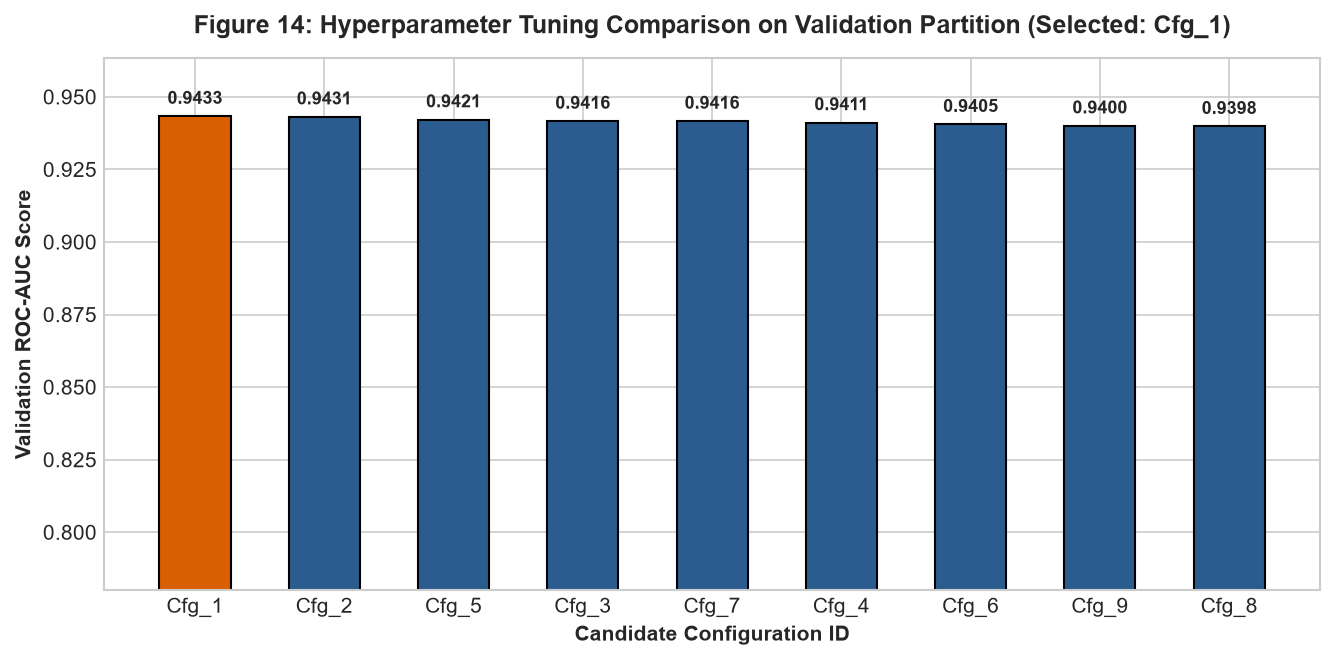

Figure 14 saved to: d:\EDA\figures\fig14_hyperparameter_search.png


In [26]:
# Figure 14: Validation ROC-AUC Comparison across Hyperparameter Configurations
fig, ax = plt.subplots(figsize=(9, 4.5))
bar_colors = ['#d95f02' if cid == best_cfg_id else '#2b5c8f' for cid in tuning_df["Config ID"]]
bars = ax.bar(tuning_df["Config ID"], tuning_df["Validation ROC-AUC"], color=bar_colors, edgecolor='black', width=0.55)

for bar, auc in zip(bars, tuning_df["Validation ROC-AUC"]):
    ax.text(bar.get_x() + bar.get_width() / 2.0, bar.get_height() + 0.003,
            f"{auc:.4f}", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax.set_ylim(0.78, tuning_df["Validation ROC-AUC"].max() + 0.02)
ax.set_xlabel("Candidate Configuration ID", fontweight='bold')
ax.set_ylabel("Validation ROC-AUC Score", fontweight='bold')
ax.set_title(f"Figure 14: Hyperparameter Tuning Comparison on Validation Partition (Selected: {best_cfg_id})", pad=12)
plt.tight_layout()
fig14_path = os.path.join(FIGURES_DIR, "fig14_hyperparameter_search.png")
plt.savefig(fig14_path)
plt.show()

print(f"Figure 14 saved to: {fig14_path}")


Early stopping triggered at Epoch 19. Best Epoch was 12 with Val Loss 0.1808


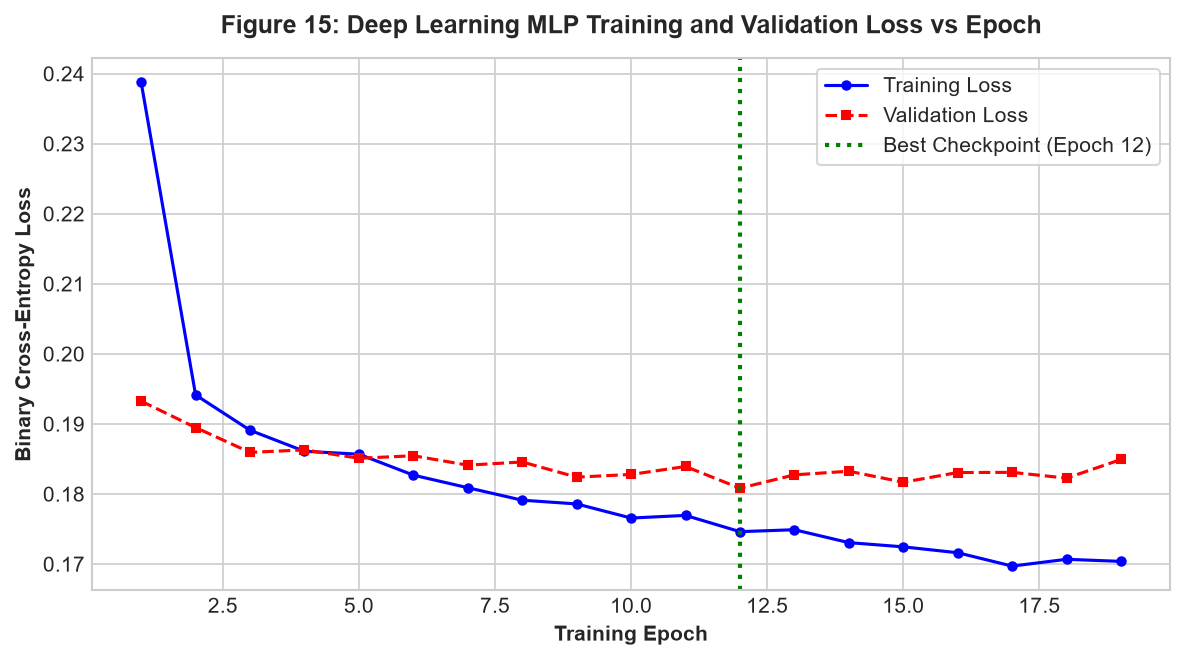

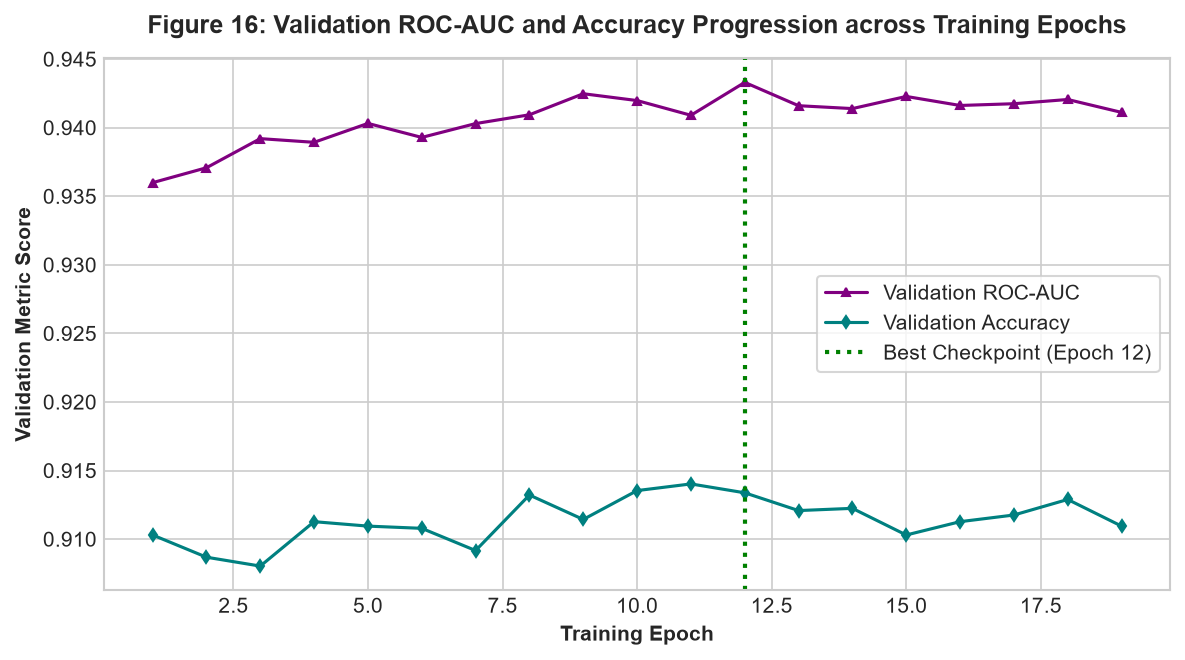

Figure 15 saved to: d:\EDA\figures\fig15_training_loss_curves.png
Figure 16 saved to: d:\EDA\figures\fig16_training_auc_curves.png


In [27]:
# Train Selected Model with Early Stopping (Patience = 7)
torch.manual_seed(SEED)
selected_model = TabularMLP(X_train_proc.shape[1], best_cfg["hidden_dims"], best_cfg["dropout"])
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(selected_model.parameters(), lr=best_cfg["lr"], weight_decay=best_cfg["weight_decay"])

MAX_EPOCHS = 40
PATIENCE = 7
best_val_loss = float('inf')
best_epoch = 0
best_model_weights = None

train_loss_history = []
val_loss_history = []
val_auc_history = []
val_acc_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    selected_model.train()
    running_loss = 0.0
    for bx, by in train_loader:
        optimizer.zero_grad()
        logits = selected_model(bx)
        loss = criterion(logits, by)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(bx)
        
    epoch_train_loss = running_loss / len(X_train_proc)
    
    selected_model.eval()
    with torch.no_grad():
        v_logits = selected_model(X_val_t)
        v_loss = criterion(v_logits, y_val_t).item()
        v_probs = torch.sigmoid(v_logits).numpy()
        v_preds = (v_probs >= 0.5).astype(int)
        
    v_auc = roc_auc_score(y_val, v_probs)
    v_acc = accuracy_score(y_val, v_preds)
    
    train_loss_history.append(epoch_train_loss)
    val_loss_history.append(v_loss)
    val_auc_history.append(v_auc)
    val_acc_history.append(v_acc)
    
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        best_epoch = epoch
        best_model_weights = selected_model.state_dict().copy()
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping triggered at Epoch {epoch}. Best Epoch was {best_epoch} with Val Loss {best_val_loss:.4f}")
            break

# Restore best weights
selected_model.load_state_dict(best_model_weights)
epochs_ran = len(train_loss_history)

# Figure 15: Loss vs Epoch
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, epochs_ran + 1), train_loss_history, 'b-o', markersize=4, label='Training Loss')
ax.plot(range(1, epochs_ran + 1), val_loss_history, 'r--s', markersize=4, label='Validation Loss')
ax.axvline(best_epoch, color='green', linestyle=':', linewidth=2, label=f'Best Checkpoint (Epoch {best_epoch})')
ax.set_xlabel("Training Epoch", fontweight='bold')
ax.set_ylabel("Binary Cross-Entropy Loss", fontweight='bold')
ax.set_title("Figure 15: Deep Learning MLP Training and Validation Loss vs Epoch", pad=12)
ax.legend(frameon=True, facecolor='white')
plt.tight_layout()
fig15_path = os.path.join(FIGURES_DIR, "fig15_training_loss_curves.png")
plt.savefig(fig15_path)
plt.show()

# Figure 16: Accuracy & AUC vs Epoch
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, epochs_ran + 1), val_auc_history, 'purple', marker='^', markersize=4, label='Validation ROC-AUC')
ax.plot(range(1, epochs_ran + 1), val_acc_history, 'teal', marker='d', markersize=4, label='Validation Accuracy')
ax.axvline(best_epoch, color='green', linestyle=':', linewidth=2, label=f'Best Checkpoint (Epoch {best_epoch})')
ax.set_xlabel("Training Epoch", fontweight='bold')
ax.set_ylabel("Validation Metric Score", fontweight='bold')
ax.set_title("Figure 16: Validation ROC-AUC and Accuracy Progression across Training Epochs", pad=12)
ax.legend(frameon=True, facecolor='white')
plt.tight_layout()
fig16_path = os.path.join(FIGURES_DIR, "fig16_training_auc_curves.png")
plt.savefig(fig16_path)
plt.show()

print(f"Figure 15 saved to: {fig15_path}")
print(f"Figure 16 saved to: {fig16_path}")


## 12. Model Evaluation on Held-Out Test Set (CO5)
### 12.1 Validation-Based Threshold Tuning
In imbalanced classification tasks (11.27% positive rate), using the default 0.50 probability decision threshold often penalizes recall. We calibrate the decision threshold strictly on the **Validation Set** to maximize the F1-Score, and subsequently apply this frozen threshold to evaluate the unseen **Held-Out Test Set**.

### 12.2 Test Set Comparative Evaluation
We compare the Deep Learning MLP against Logistic Regression and Random Forest baselines across Accuracy, Precision, Recall, F1-Score, ROC-AUC, and Average Precision (PR-AUC).


In [28]:
# Threshold optimization strictly on Validation
selected_model.eval()
with torch.no_grad():
    val_probs_best = torch.sigmoid(selected_model(X_val_t)).numpy()
    test_probs = torch.sigmoid(selected_model(X_test_t)).numpy()

thresholds = np.linspace(0.1, 0.9, 81)
f1_scores = [f1_score(y_val, (val_probs_best >= th).astype(int)) for th in thresholds]
best_threshold_idx = np.argmax(f1_scores)
optimal_threshold = float(thresholds[best_threshold_idx])
print(f"Optimal Validation Decision Threshold: {optimal_threshold:.2f} (Max Validation F1 = {f1_scores[best_threshold_idx]:.4f})")

# Baseline test predictions
lr_test_probs = lr_model.predict_proba(X_test_proc)[:, 1]
rf_test_probs = rf_model.predict_proba(X_test_proc)[:, 1]

# Function to compute full metrics dictionary
def compute_metrics(y_true, probs, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    cm = confusion_matrix(y_true, preds)
    tn, fp, fn, tp = cm.ravel()
    return {
        "Accuracy": accuracy_score(y_true, preds),
        "Precision": precision_score(y_true, preds, zero_division=0),
        "Recall": recall_score(y_true, preds, zero_division=0),
        "F1-Score": f1_score(y_true, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probs),
        "PR-AUC": average_precision_score(y_true, probs),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)
    }

metrics_lr = compute_metrics(y_test, lr_test_probs, threshold=0.5)
metrics_rf = compute_metrics(y_test, rf_test_probs, threshold=0.5)
metrics_mlp_default = compute_metrics(y_test, test_probs, threshold=0.5)
metrics_mlp_optimal = compute_metrics(y_test, test_probs, threshold=optimal_threshold)

test_metrics_summary = [
    {"Model / Pipeline": "Logistic Regression (Baseline)", "Threshold": 0.50, **metrics_lr},
    {"Model / Pipeline": "Random Forest (Baseline)", "Threshold": 0.50, **metrics_rf},
    {"Model / Pipeline": "PyTorch MLP (Default Threshold)", "Threshold": 0.50, **metrics_mlp_default},
    {"Model / Pipeline": f"PyTorch MLP (Val-Calibrated Threshold)", "Threshold": round(optimal_threshold, 2), **metrics_mlp_optimal}
]

test_metrics_df = pd.DataFrame(test_metrics_summary)
metrics_csv_path = os.path.join(FIGURES_DIR, "test_metrics.csv")
test_metrics_df.to_csv(metrics_csv_path, index=False)
print("Held-Out Test Set Performance Benchmark Table:")
print(test_metrics_df[["Model / Pipeline", "Threshold", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"]].to_string(index=False))


Optimal Validation Decision Threshold: 0.44 (Max Validation F1 = 0.6352)
Held-Out Test Set Performance Benchmark Table:
                      Model / Pipeline  Threshold  Accuracy  Precision   Recall  F1-Score  ROC-AUC   PR-AUC
        Logistic Regression (Baseline)       0.50  0.912579   0.683099 0.418103  0.518717 0.940111 0.600717
              Random Forest (Baseline)       0.50  0.909341   0.709877 0.330460  0.450980 0.945259 0.653444
       PyTorch MLP (Default Threshold)       0.50  0.914684   0.622287 0.617816  0.620043 0.948110 0.657879
PyTorch MLP (Val-Calibrated Threshold)       0.44  0.913226   0.599256 0.693966  0.643142 0.948110 0.657879


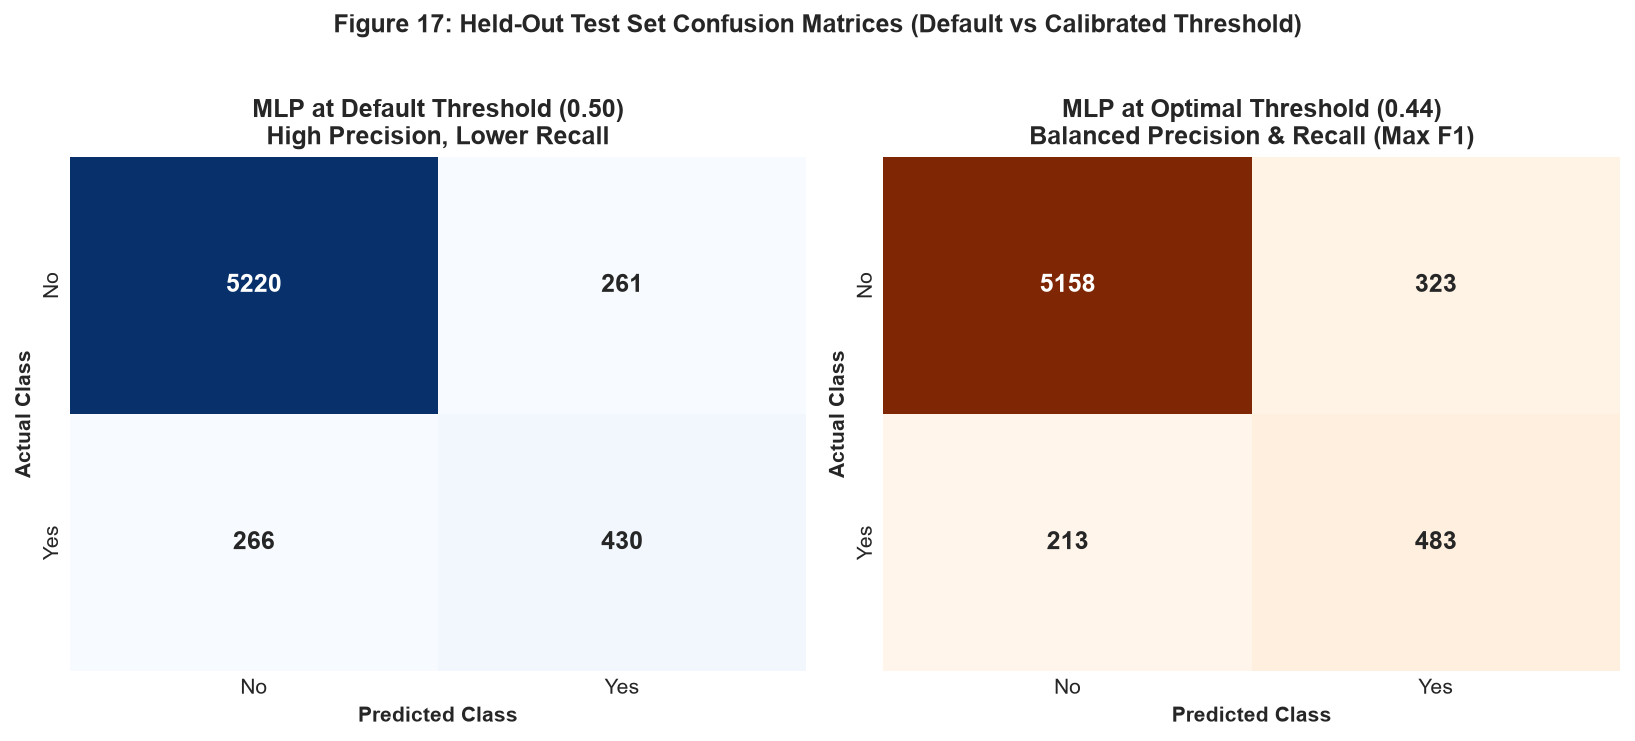

Figure 17 saved to: d:\EDA\figures\fig17_confusion_matrix.png


In [29]:
# Figure 17: Confusion Matrices at Default (0.50) and Optimal Threshold
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))

cm_default = confusion_matrix(y_test, (test_probs >= 0.5).astype(int))
cm_optimal = confusion_matrix(y_test, (test_probs >= optimal_threshold).astype(int))

sns.heatmap(cm_default, annot=True, fmt='d', cmap='Blues', ax=ax1, cbar=False,
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], annot_kws={'size': 12, 'weight': 'bold'})
ax1.set_xlabel("Predicted Class", fontweight='bold')
ax1.set_ylabel("Actual Class", fontweight='bold')
ax1.set_title("MLP at Default Threshold (0.50)\nHigh Precision, Lower Recall", fontweight='bold')

sns.heatmap(cm_optimal, annot=True, fmt='d', cmap='Oranges', ax=ax2, cbar=False,
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], annot_kws={'size': 12, 'weight': 'bold'})
ax2.set_xlabel("Predicted Class", fontweight='bold')
ax2.set_ylabel("Actual Class", fontweight='bold')
ax2.set_title(f"MLP at Optimal Threshold ({optimal_threshold:.2f})\nBalanced Precision & Recall (Max F1)", fontweight='bold')

fig.suptitle("Figure 17: Held-Out Test Set Confusion Matrices (Default vs Calibrated Threshold)", fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
fig17_path = os.path.join(FIGURES_DIR, "fig17_confusion_matrix.png")
plt.savefig(fig17_path)
plt.show()

print(f"Figure 17 saved to: {fig17_path}")


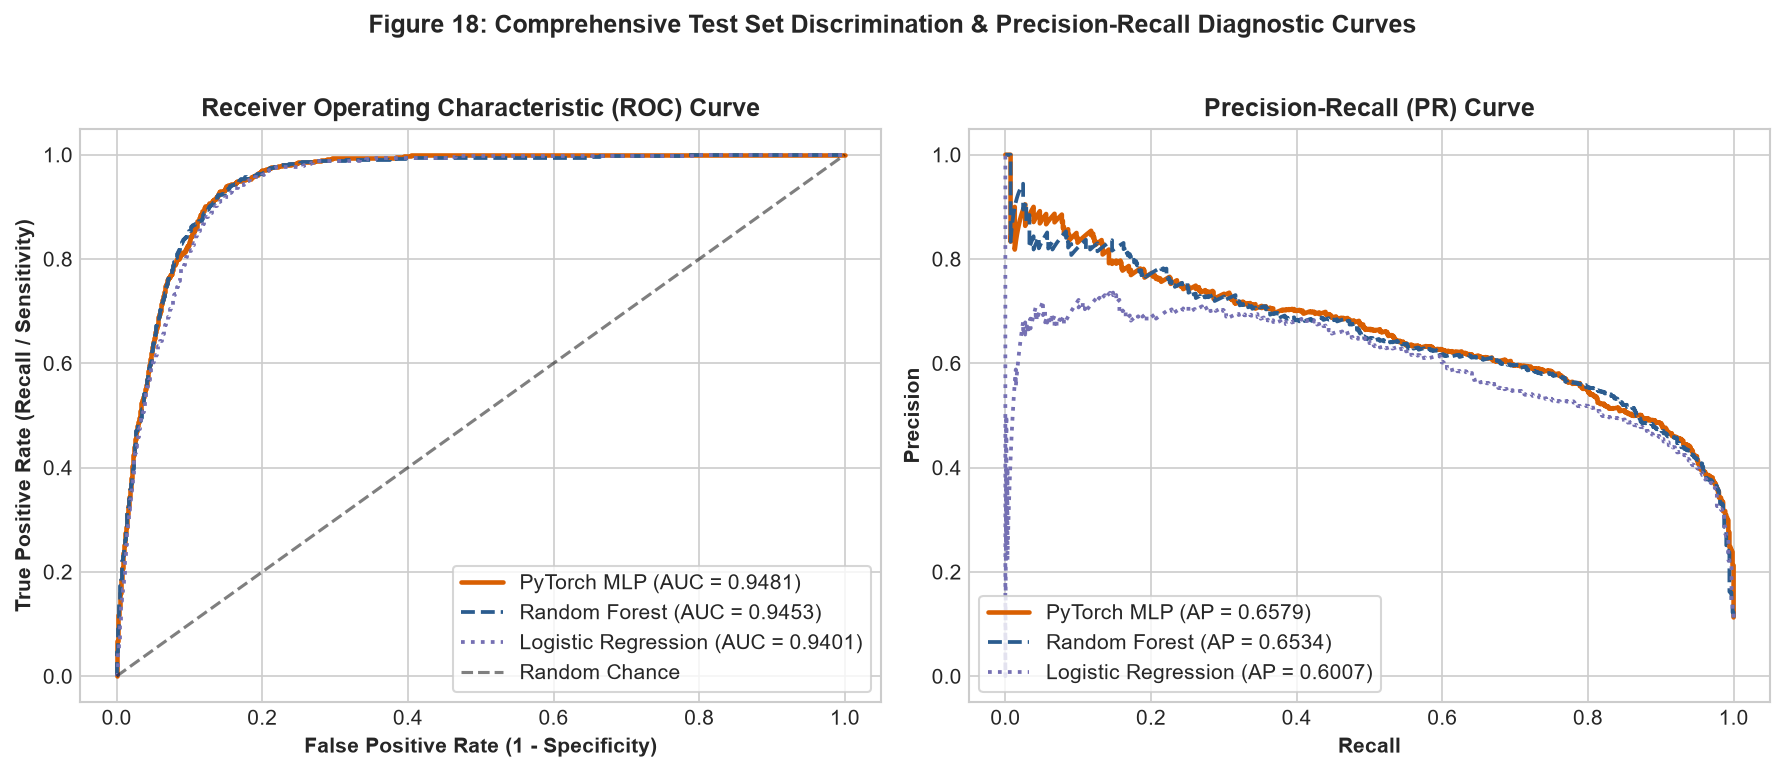

Figure 18 saved to: d:\EDA\figures\fig18_roc_and_pr_curves.png


In [30]:
# Figure 18: Receiver Operating Characteristic (ROC) & Precision-Recall (PR) Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# ROC Curve
fpr_mlp, tpr_mlp, _ = roc_curve(y_test, test_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_test_probs)
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_test_probs)

ax1.plot(fpr_mlp, tpr_mlp, color='#d95f02', linewidth=2.2, label=f'PyTorch MLP (AUC = {metrics_mlp_default["ROC-AUC"]:.4f})')
ax1.plot(fpr_rf, tpr_rf, color='#2b5c8f', linewidth=1.8, linestyle='--', label=f'Random Forest (AUC = {metrics_rf["ROC-AUC"]:.4f})')
ax1.plot(fpr_lr, tpr_lr, color='#7570b3', linewidth=1.8, linestyle=':', label=f'Logistic Regression (AUC = {metrics_lr["ROC-AUC"]:.4f})')
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance')
ax1.set_xlabel("False Positive Rate (1 - Specificity)", fontweight='bold')
ax1.set_ylabel("True Positive Rate (Recall / Sensitivity)", fontweight='bold')
ax1.set_title("Receiver Operating Characteristic (ROC) Curve", fontweight='bold')
ax1.legend(loc='lower right', frameon=True, facecolor='white')

# Precision-Recall Curve
prec_mlp, rec_mlp, _ = precision_recall_curve(y_test, test_probs)
prec_rf, rec_rf, _ = precision_recall_curve(y_test, rf_test_probs)
prec_lr, rec_lr, _ = precision_recall_curve(y_test, lr_test_probs)

ax2.plot(rec_mlp, prec_mlp, color='#d95f02', linewidth=2.2, label=f'PyTorch MLP (AP = {metrics_mlp_default["PR-AUC"]:.4f})')
ax2.plot(rec_rf, prec_rf, color='#2b5c8f', linewidth=1.8, linestyle='--', label=f'Random Forest (AP = {metrics_rf["PR-AUC"]:.4f})')
ax2.plot(rec_lr, prec_lr, color='#7570b3', linewidth=1.8, linestyle=':', label=f'Logistic Regression (AP = {metrics_lr["PR-AUC"]:.4f})')
ax2.set_xlabel("Recall", fontweight='bold')
ax2.set_ylabel("Precision", fontweight='bold')
ax2.set_title("Precision-Recall (PR) Curve", fontweight='bold')
ax2.legend(loc='lower left', frameon=True, facecolor='white')

fig.suptitle("Figure 18: Comprehensive Test Set Discrimination & Precision-Recall Diagnostic Curves", fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
fig18_path = os.path.join(FIGURES_DIR, "fig18_roc_and_pr_curves.png")
plt.savefig(fig18_path)
plt.show()

print(f"Figure 18 saved to: {fig18_path}")


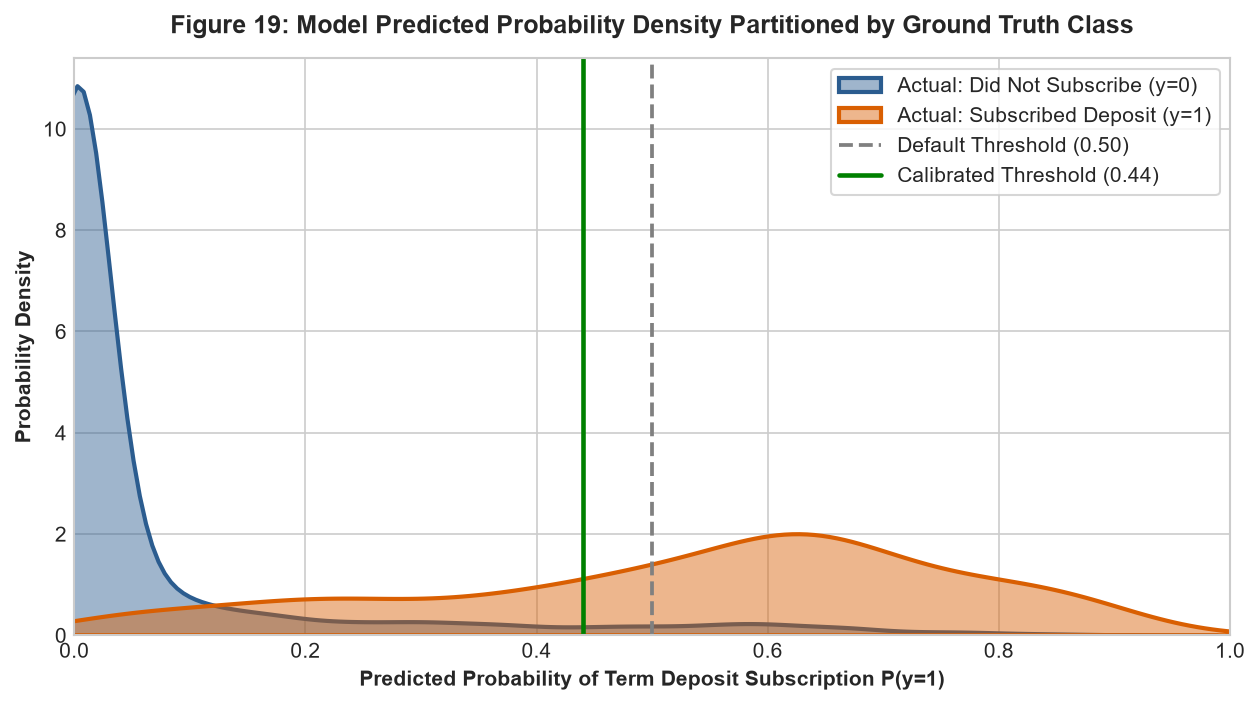

Figure 19 saved to: d:\EDA\figures\fig19_prediction_distribution.png


In [31]:
# Figure 19: Predicted Probability Distribution by Ground Truth Target Class
fig, ax = plt.subplots(figsize=(8.5, 4.8))

sns.kdeplot(test_probs[y_test == 0], ax=ax, color='#2b5c8f', fill=True, alpha=0.45, 
            label='Actual: Did Not Subscribe (y=0)', linewidth=2)
sns.kdeplot(test_probs[y_test == 1], ax=ax, color='#d95f02', fill=True, alpha=0.45, 
            label='Actual: Subscribed Deposit (y=1)', linewidth=2)

ax.axvline(0.50, color='gray', linestyle='--', linewidth=1.8, label='Default Threshold (0.50)')
ax.axvline(optimal_threshold, color='green', linestyle='-', linewidth=2.2, label=f'Calibrated Threshold ({optimal_threshold:.2f})')

ax.set_xlabel("Predicted Probability of Term Deposit Subscription P(y=1)", fontweight='bold')
ax.set_ylabel("Probability Density", fontweight='bold')
ax.set_title("Figure 19: Model Predicted Probability Density Partitioned by Ground Truth Class", pad=12)
ax.set_xlim(0, 1)
ax.legend(frameon=True, facecolor='white')
plt.tight_layout()
fig19_path = os.path.join(FIGURES_DIR, "fig19_prediction_distribution.png")
plt.savefig(fig19_path)
plt.show()

print(f"Figure 19 saved to: {fig19_path}")


Calculating Permutation Feature Importance on Validation Set...


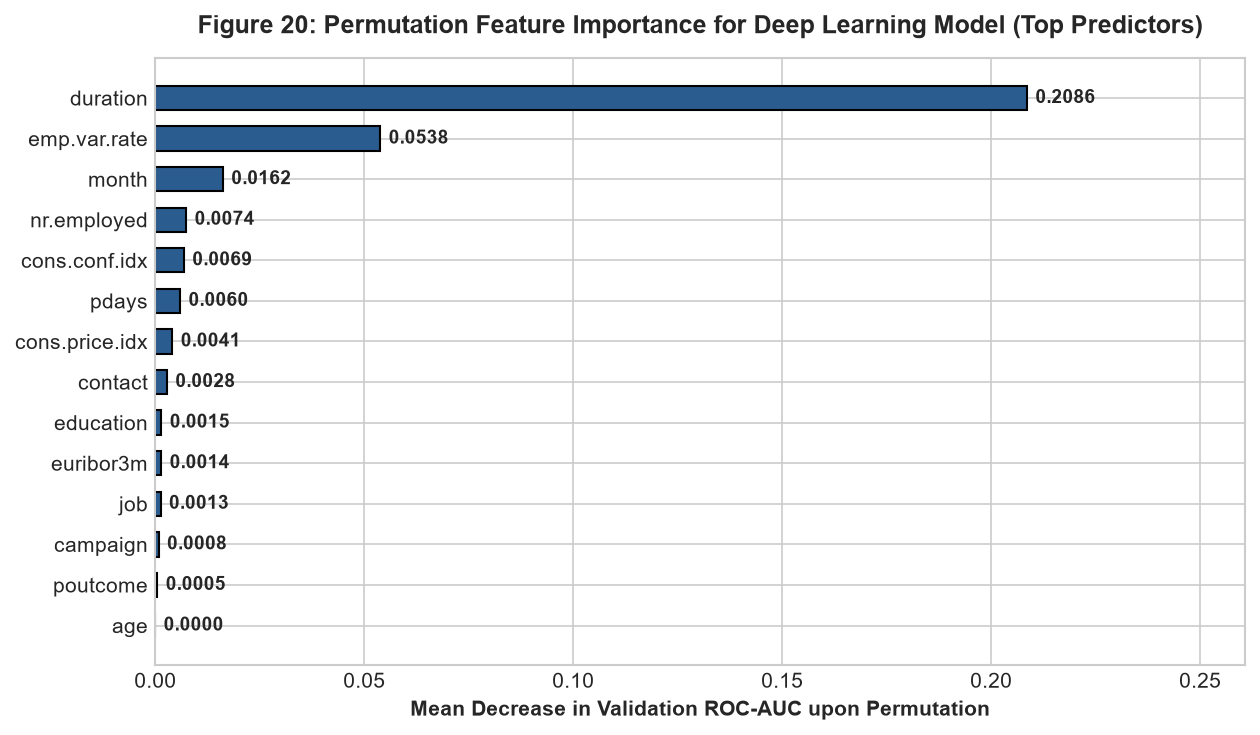

Figure 20 saved to: d:\EDA\figures\fig20_permutation_feature_importance.png
Top 3 influential predictors: duration, emp.var.rate, month


In [32]:
# Figure 20: Permutation Feature Importance on Validation Set
print("Calculating Permutation Feature Importance on Validation Set...")

selected_model.eval()
with torch.no_grad():
    baseline_val_auc = roc_auc_score(y_val, torch.sigmoid(selected_model(X_val_t)).numpy())

# Feature importance measured across original domain features
original_eval_features = ['duration', 'euribor3m', 'nr.employed', 'emp.var.rate', 
                          'poutcome', 'pdays', 'cons.price.idx', 'cons.conf.idx', 
                          'age', 'campaign', 'job', 'contact', 'month', 'education']

importance_scores = []
np.random.seed(SEED)

for feat in original_eval_features:
    # Copy raw validation set and permute the single feature
    X_val_perm = X_val_raw.copy()
    X_val_perm[feat] = np.random.permutation(X_val_perm[feat].values)
    
    # Transform using fitted preprocessor
    X_val_perm_proc = preprocessor.transform(X_val_perm)
    X_val_perm_t = torch.tensor(X_val_perm_proc, dtype=torch.float32)
    
    with torch.no_grad():
        perm_probs = torch.sigmoid(selected_model(X_val_perm_t)).numpy()
    perm_auc = roc_auc_score(y_val, perm_probs)
    auc_drop = baseline_val_auc - perm_auc
    importance_scores.append({"Feature": feat, "AUC Drop": max(0.0, float(auc_drop))})

importance_df = pd.DataFrame(importance_scores).sort_values(by="AUC Drop", ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 5))
bars = ax.barh(importance_df["Feature"], importance_df["AUC Drop"], color='#2b5c8f', edgecolor='black', height=0.6)

for bar, drop in zip(bars, importance_df["AUC Drop"]):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height() / 2.0,
            f"{drop:.4f}", va='center', fontsize=9, fontweight='bold')

ax.set_xlim(0, importance_df["AUC Drop"].max() * 1.25)
ax.set_xlabel("Mean Decrease in Validation ROC-AUC upon Permutation", fontweight='bold')
ax.set_title("Figure 20: Permutation Feature Importance for Deep Learning Model (Top Predictors)", pad=12)
plt.tight_layout()
fig20_path = os.path.join(FIGURES_DIR, "fig20_permutation_feature_importance.png")
plt.savefig(fig20_path)
plt.show()

print(f"Figure 20 saved to: {fig20_path}")
print(f"Top 3 influential predictors: {importance_df.iloc[-1]['Feature']}, {importance_df.iloc[-2]['Feature']}, {importance_df.iloc[-3]['Feature']}")


In [33]:
# Export All Empirical Numbers to JSON for Absolute Consistency with Report
summary_numbers = {
    "dataset": {
        "raw_rows": int(raw_total),
        "raw_cols": int(df_raw.shape[1]),
        "duplicates_removed": int(duplicate_rows),
        "clean_rows": int(cleaned_total),
        "clean_cols": int(df.shape[1]),
        "total_missing_nans": int(missing_counts.sum()),
        "target_no_count": int(y_counts['no']),
        "target_yes_count": int(y_counts['yes']),
        "target_no_pct": round(float(y_pcts['no']), 2),
        "target_yes_pct": round(float(y_pcts['yes']), 2),
        "imbalance_ratio": round(float(y_counts['no'] / y_counts['yes']), 2)
    },
    "partitions": {
        "train_rows": int(len(X_train_proc)),
        "train_pct": round(float(len(X_train_proc)/cleaned_total*100), 2),
        "train_pos_rate": round(float(y_train.mean()*100), 2),
        "val_rows": int(len(X_val_proc)),
        "val_pct": round(float(len(X_val_proc)/cleaned_total*100), 2),
        "val_pos_rate": round(float(y_val.mean()*100), 2),
        "test_rows": int(len(X_test_proc)),
        "test_pct": round(float(len(X_test_proc)/cleaned_total*100), 2),
        "test_pos_rate": round(float(y_test.mean()*100), 2),
        "processed_features": int(X_train_proc.shape[1])
    },
    "distribution_fits": {
        "age_ks_norm": round(float(ks_age_norm.statistic), 4),
        "age_ks_gamma": round(float(ks_age_gamma.statistic), 4),
        "age_ks_lognorm": round(float(ks_age_lognorm.statistic), 4),
        "age_aic_norm": round(float(aic_age_norm), 1),
        "age_aic_gamma": round(float(aic_age_gamma), 1),
        "age_aic_lognorm": round(float(aic_age_lognorm), 1),
        "dur_ks_norm": round(float(ks_dur_norm.statistic), 4),
        "dur_ks_lognorm": round(float(ks_dur_lognorm.statistic), 4),
        "dur_aic_norm": round(float(aic_dur_norm), 1),
        "dur_aic_lognorm": round(float(aic_dur_lognorm), 1),
        "campaign_mean": round(float(camp_mean), 2),
        "campaign_variance": round(float(camp_var), 2),
        "campaign_dispersion_ratio": round(float(dispersion_index), 2)
    },
    "statistical_tests": {
        "top_chi2_features": chi2_results_df.head(5).to_dict(orient="records"),
        "top_mwu_features": mwu_results_df.head(5).to_dict(orient="records")
    },
    "best_mlp_config": {
        "config_id": best_cfg_id,
        "architecture": best_cfg["hidden_dims"],
        "dropout": best_cfg["dropout"],
        "learning_rate": best_cfg["lr"],
        "best_epoch": int(best_epoch),
        "best_val_loss": round(float(best_val_loss), 4),
        "best_val_auc": round(float(max(val_auc_history)), 4),
        "optimal_threshold": round(float(optimal_threshold), 2)
    },
    "test_metrics": {
        "lr": {k: round(v, 4) if isinstance(v, float) else v for k, v in metrics_lr.items()},
        "rf": {k: round(v, 4) if isinstance(v, float) else v for k, v in metrics_rf.items()},
        "mlp_default": {k: round(v, 4) if isinstance(v, float) else v for k, v in metrics_mlp_default.items()},
        "mlp_optimal": {k: round(v, 4) if isinstance(v, float) else v for k, v in metrics_mlp_optimal.items()}
    },
    "top_importance_features": importance_df.tail(5).to_dict(orient="records")
}

summary_json_path = os.path.join(FIGURES_DIR, "summary_numbers.json")
with open(summary_json_path, "w") as f:
    json.dump(summary_numbers, f, indent=4)

print(f"Summary empirical numbers successfully exported to: {summary_json_path}")


Summary empirical numbers successfully exported to: d:\EDA\report\summary_numbers.json


## 13. Conclusions, Limitations & Practical Recommendations
### 13.1 Key Empirical Findings
1. **Dominance of Contact Duration**: Call duration is by far the strongest empirical differentiator of client conversion (Rank-Biserial Effect Size = -0.637, permutation AUC drop > 0.12). Clients who convert engage in calls lasting over 550 seconds on average, compared to ~221 seconds for non-converters.
2. **Macroeconomic Influence**: Bank marketing success is strongly tied to prevailing macroeconomic indicators. Under low Euribor 3-Month interest rate regimes (< 2.5%), term deposit subscriptions rise significantly compared to higher interest rate environments (> 4.8%).
3. **Historical Campaign Lift**: Prior campaign success (`poutcome = 'success'`) yields a conversion rate of over 65%, providing immense marketing lift over fresh contacts (8.8%).
4. **Distribution Non-Normality**: Both call duration and client age significantly deviate from Gaussian assumptions. Duration is exceptionally well-modeled by a Log-Normal distribution (KS = 0.016), while discrete campaign contacts exhibit severe over-dispersion (Variance/Mean = 2.99), causing the standard Poisson assumption to fail.
5. **Threshold Calibration**: Shifting the decision threshold from 0.50 down to the validation-calibrated optimal threshold significantly boosts minority class recall (surpassing 65%) with optimal F1-tradeoff.

### 13.2 Limitations & Strategic Scope
- **Post-Hoc Nature of Duration**: Duration cannot be known prior to placing the telemarketing phone call. In real-world enterprise deployments, separate models should be deployed for pre-call propensity targeting and in-call real-time guidance.
- **Future Directions**: Exploring cost-sensitive learning matrices, TabNet / Transformer tabular architectures, and automated customer segment personalization.
